In [3]:
import sunpy
import sunpy.timeseries 
from sunpy.net import Fido, attrs as a
import matplotlib.pyplot as plt
import sunpy.map
import numpy as np
import webbrowser
from pathlib import Path
from urllib.request import urlretrieve
from astropy.io import fits
from datetime import date
import time
from astropy.time import Time
import matplotlib.dates as mdates
from datetime import datetime, timedelta
from astropy.visualization import time_support
from sunpy import timeseries as ts
import csv
import pandas as pd
import astropy.units as u
from scipy.signal import savgol_filter
from scipy import stats

/Users/scottd/miniforge3/envs/sunpy-clean/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# ---------------------------------------------------------
# CONFIGURATION
# ---------------------------------------------------------

tstart = '2010/05/01 07:23:56'
tend = '2012/10/11 12:40:29'

event_type = 'FL'
min_flare_class = 'M1.0'

DEBUGGING = False

# Minimum separation between flare peak times (minutes).
# Events closer than this are considered potentially identical.
MIN_PEAK_SEPARATION = 10

# Minimum separation between event intervals.
# Overlapping events are treated as potential duplicates.
MIN_EVENT_SEPARATION = 0

# Exclude events too close to disk centre (arcsec).
# Set to 0 to disable this criterion.
MIN_DISK_DISTANCE = 0.1

# File locations
CSV_FILE = Path('flares_data.csv')
EVE_DIRECTORY = Path('./EVL_L2_files_Mk2/')
XRS_DIRECTORY = Path('./GOES_XRS_Data_MK2/')

EVE_DIRECTORY.mkdir(parents=True, exist_ok=True)
XRS_DIRECTORY.mkdir(parents=True, exist_ok=True)


In [5]:

# ---------------------------------------------------------
# HELPER FUNCTIONS
# ---------------------------------------------------------


def get_time(flare, key):
    """Convert HEK time to Astropy Time."""
    return Time(str(flare[key]))

def is_duplicate(flare, accepted_flares):
    """
    Check whether an event is sufficiently different
    from previously accepted events.

    Events are considered duplicates if their peak times
    are too close OR their event intervals overlap.
    """

    start = get_time(flare, 'event_starttime')
    peak = get_time(flare, 'event_peaktime')
    end = get_time(flare, 'event_endtime')

    for previous in accepted_flares:

        p_start = previous['start']
        p_peak = previous['peak']
        p_end = previous['end']

        peak_separation = abs(
            (peak - p_peak).to_value('sec')
        ) / 60

        # Time interval separation, zero if intervals overlap.
        if start > p_end:
            interval_separation = (
                start - p_end
            ).to_value('sec') / 60

        elif p_start > end:
            interval_separation = (
                p_start - end
            ).to_value('sec') / 60

        else:
            interval_separation = 0

        if (
            peak_separation < MIN_PEAK_SEPARATION
            or interval_separation <= MIN_EVENT_SEPARATION
        ):
            return True

    return False


def get_eve_filename(peak):
    """Generate the EVE level 2 line-data filename."""

    year = int(peak.ymdhms.year)
    month = int(peak.ymdhms.month)
    day = int(peak.ymdhms.day)
    hour = int(peak.ymdhms.hour)

    doy = date(year, month, day).timetuple().tm_yday

    version = 8
    revision = 1

    filename = (
        f'EVL_L2_{year}{doy:03d}_{hour:02d}_'
        f'{version:03d}_{revision:02d}.fit.gz'
    )

    url = (
        'https://lasp.colorado.edu/eve/data_access/'
        f'evewebdata/products/level2/{year}/'
        f'{doy:03d}/{filename}'
    )

    return filename, url


def download_eve(peak):
    """
    Download EVE files for the hour before, during,
    and after the flare peak.

    Files are checked individually to avoid duplicates.
    """

    import requests

    downloaded_files = []
    statuses = []

    # Previous hour, flare hour, following hour
    for hour_offset in [-1, 0, 1]:

        file_time = peak + hour_offset * u.hour

        filename, url = get_eve_filename(file_time)

        filepath = EVE_DIRECTORY / filename

        if filepath.exists():
            downloaded_files.append(str(filepath))
            statuses.append('Already downloaded')
            continue

        if DEBUGGING:
            downloaded_files.append(str(filepath))
            statuses.append('Debug mode')
            continue

        try:
            response = requests.get(url, timeout=60)
            response.raise_for_status()

            filepath.write_bytes(response.content)

            downloaded_files.append(str(filepath))
            statuses.append('Downloaded')

        except Exception as error:

            downloaded_files.append('')
            statuses.append(f'Failed: {error}')

    return (
        ';'.join(downloaded_files),
        ';'.join(statuses)
    )
    


def download_xrs(peak):
    """
    Download GOES XRS data for the actual flare date.

    If the flare occurs within one hour of midnight:
      - Before midnight: also download the following day.
      - After midnight: also download the previous day.

    The actual flare date is ALWAYS downloaded.
    """

    if DEBUGGING:
        return '', 'Debug mode'

    try:

        # Actual flare date
        flare_date = peak.to_datetime().date()

        # Determine time since midnight
        dt = peak.to_datetime()

        minutes_since_midnight = (
            dt.hour * 60 + dt.minute + dt.second / 60
        )

        # Always include the actual flare date
        dates_to_download = [flare_date]

        # Within first hour after midnight:
        # Also download previous day
        if minutes_since_midnight < 60:

            previous_day = flare_date - timedelta(days=1)

            dates_to_download.append(previous_day)

        # Within last hour before midnight:
        # Also download following day
        elif minutes_since_midnight >= 23 * 60:

            following_day = flare_date + timedelta(days=1)

            dates_to_download.append(following_day)

        downloaded_files = []

        for search_date in dates_to_download:

            # Search the complete calendar day
            start = datetime.combine(
                search_date,
                datetime.min.time()
            )

            end = start + timedelta(days=1)

            search = Fido.search(
                a.Time(start, end),
                a.Instrument("XRS"),
                a.Resolution("flx1s")
            )

            if len(search) == 0:
                print(f"No XRS data found for {search_date}")
                continue

            files = Fido.fetch(
                search,
                path=str(XRS_DIRECTORY / '{file}')
            )

            for filename in files:

                filename = str(filename)

                if filename not in downloaded_files:
                    downloaded_files.append(filename)

        if not downloaded_files:

            return '', 'No XRS data found'

        return (
            ';'.join(downloaded_files),
            'Downloaded'
        )

    except Exception as error:

        return '', f'XRS download failed: {error}'


In [4]:

# ---------------------------------------------------------
# SEARCH HEK
# ---------------------------------------------------------

print('Searching HEK...')

result = Fido.search(
    a.Time(tstart, tend),
    a.hek.EventType(event_type),
    a.hek.FL.GOESCls >= min_flare_class
)

hek_results = result['hek']

print(f'HEK events found: {len(hek_results)}')


# ---------------------------------------------------------
# PROCESS EVENTS
# ---------------------------------------------------------

accepted_flares = []

statistics = {
    'invalid_position': 0,
    'too_close_to_centre': 0,
    'duplicate': 0,
    'accepted': 0,
    'eve_failed': 0,
    'xrs_failed': 0
}


with open(CSV_FILE, 'w', newline='') as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow([
        'Flare',
        'event_starttime',
        'event_peaktime',
        'event_endtime',
        'flare_class',
        'hgs_x',
        'hgs_y',
        'distance_from_disk_centre',
        'EVE_files',
        'EVE_status',
        'XRS_files',
        'XRS_status'
    ])

    for i, flare in enumerate(hek_results):

        try:

            # ---------------------------------------------
            # POSITION CHECK
            # ---------------------------------------------

            x = float(flare['hgs_x'])
            y = float(flare['hgs_y'])

            if not np.isfinite(x) or not np.isfinite(y):
                statistics['invalid_position'] += 1
                continue

            distance = np.hypot(x, y)

            if distance < MIN_DISK_DISTANCE:
                statistics['too_close_to_centre'] += 1
                continue

            # ---------------------------------------------
            # TIME CHECK
            # ---------------------------------------------

            start = get_time(flare, 'event_starttime')
            peak = get_time(flare, 'event_peaktime')
            end = get_time(flare, 'event_endtime')

            if is_duplicate(flare, accepted_flares):
                statistics['duplicate'] += 1
                continue

            # Only accept the flare after passing checks.
            accepted_flares.append({
                'start': start,
                'peak': peak,
                'end': end
            })

            statistics['accepted'] += 1

            # ---------------------------------------------
            # DOWNLOAD EVE
            # ---------------------------------------------

            eve_file, eve_status = download_eve(peak)

            if 'failed' in eve_status.lower():
                statistics['eve_failed'] += 1

            # ---------------------------------------------
            # DOWNLOAD XRS
            # ---------------------------------------------

            xrs_file, xrs_status = download_xrs(peak)

            if 'failed' in xrs_status.lower():
                statistics['xrs_failed'] += 1

            # ---------------------------------------------
            # WRITE CSV
            # ---------------------------------------------

            writer.writerow([
                i,
                str(start),
                str(peak),
                str(end),
                flare['fl_goescls'],
                x,
                y,
                distance,
                eve_file,       # All three EVE file paths
                eve_status,
                xrs_file,       # All downloaded XRS file paths
                xrs_status
            ])
            
            csvfile.flush()

            print(
                f'[{i}] Accepted flare: '
                f'{flare["fl_goescls"]} '
                f'at {peak}'
            )

        except Exception as error:

            print(f'Error processing event {i}: {error}')


# ---------------------------------------------------------
# SUMMARY
# ---------------------------------------------------------

print('\nPROCESSING COMPLETE')

for key, value in statistics.items():
    print(f'{key}: {value}')

print(f'\nCSV saved to: {CSV_FILE}')

Searching HEK...
HEK events found: 512


Files Downloaded: 100%|████████████████████████████████████████████████████████████| 2/2 [00:00<00:00,  3.85file/s]


[0] Accepted flare: M1.2 at 2010-05-05 17:19:00.000


Files Downloaded: 100%|████████████████████████████████████████████████████████████| 2/2 [00:00<00:00,  3.75file/s]


[2] Accepted flare: M2.0 at 2010-06-12 00:57:00.000


Files Downloaded: 100%|████████████████████████████████████████████████████████████| 2/2 [00:00<00:00,  3.76file/s]


... (479 outputs left out)

Files Downloaded:   0%|                                                                    | 0/4 [00:00<?, ?file/s]



sci_gxrs-l2-irrad_g15_d20121010_v0-1-0.nc:   0%|                                        | 0.00/797k [00:00<?, ?B/s]

Files Downloaded:  25%|███████████████                                             | 1/4 [00:00<00:01,  1.88file/s]



sci_gxrs-l2-irrad_g15_d20121010_v0-1-0.nc:   0%|                               | 1.02k/797k [00:00<03:33, 3.73kB/s]

sci_gxrs-l2-irrad_g14_d20121010_v0-1-0.nc:   0%|                               | 1.02k/870k [00:00<03:54, 3.71kB/s]



sci_gxrs-l2-irrad_g15_d20121010_v0-1-0.nc:   1%|▎                              | 8.78k/797k [00:00<00:28, 28.1kB/s]

sci_gxrs-l2-irrad_g14_d20121010_v0-1-0.nc:   3%|▊                              | 24.3k/870k [00:00<00:11, 76.2kB/s]



sci_gxrs-l2-irrad_g15_d20121010_v0-1-0.nc:   4%|█▎                             | 33.3k/797k [00:00<00:08, 95.4kB/s]

sci_gxrs-l2-irrad_g14_d20121010_v0-1-0.nc:  15%|████▉   

[508] Accepted flare: M1.7 at 2012-10-09 23:31:00.000


Files Downloaded: 100%|████████████████████████████████████████████████████████████| 4/4 [00:00<00:00,  7.66file/s]

[510] Accepted flare: M1.0 at 2012-10-10 05:04:00.000

PROCESSING COMPLETE
invalid_position: 0
too_close_to_centre: 0
duplicate: 268
accepted: 244
eve_failed: 0
xrs_failed: 0

CSV saved to: flares_data.csv


In [6]:
# ---------------------------------------------------------
# HELPER FUNCTIONS
# ---------------------------------------------------------

def parse_time(value):
    """Convert CSV timestamp to Python datetime."""
    return datetime.fromisoformat(str(value).strip().replace('Z', '+00:00'))


def time_add(date_string, time_change):
    """Add minutes to a timestamp."""

    dt = parse_time(date_string)

    return dt + timedelta(minutes=time_change)


def split_files(value):
    """Extract all file paths from a semicolon-separated CSV field."""

    if not value or not value.strip():
        return []

    return [
        Path(f.strip())
        for f in value.split(';')
        if f.strip()
    ]


def resolve_files(paths, directory):
    """
    Find all existing files.

    Supports absolute paths and older relative paths.
    """

    resolved = []

    for path in paths:

        candidates = [
            path,
            directory / path.name,
            Path("EVL_L2_files") / path.name,
            Path("GOES_XRS_Data") / path.name
        ]

        for candidate in candidates:

            if candidate.exists():
                resolved.append(candidate.resolve())
                break

        else:
            print(f"Missing file: {path}")

    # Remove duplicate paths
    return list(dict.fromkeys(resolved))


def decode_value(value):
    """Convert FITS metadata values into readable strings."""

    if isinstance(value, bytes):
        return value.decode(errors='replace').strip()

    return str(value).strip()


def normalise_dataframe_index(df):
    """Convert dataframe timestamps to UTC-naive timestamps."""

    df = df.copy()

    df.index = pd.to_datetime(df.index, utc=True).tz_localize(None)

    return df


In [7]:

# ---------------------------------------------------------
# CONFIGURATION
# ---------------------------------------------------------
testing = 0
plotting = 0



INPUT_CSV = Path("flares_data.csv")
OUTPUT_CSV = Path("ai_emission_and_flares_data.csv")

EVE_DIRECTORY = Path("./EVE_Data/").resolve()
XRS_DIRECTORY = Path("./GOES_XRS_Data/").resolve()

# Time window relative to flare peak
TIME_BEFORE = 55
TIME_AFTER = 55

# mainly for plotting 
N_LINES = 71

# Savitzky-Golay filter settings
Sav_Gol_filter=1

SG_WINDOW_LENGTH = 20   # Must be an odd integer
SG_POLYORDER = 3        # Polynomial order; must be less than window length


# ---------------------------------------------------------
# READ FLARE CSV
# ---------------------------------------------------------

flare_data = []

with open(INPUT_CSV, "r", newline="") as file:

    reader = csv.DictReader(file)

    for row in reader:

        # Support both old and updated CSV column names.

        eve_value = row.get("EVE_files", row.get("EVE_file", ""))

        xrs_value = row.get("XRS_files", row.get("XRS_file", ""))

        radius_value = row.get(
            "distance_from_disk_centre",
            row.get("distance from disk", "")
        )

        flare_data.append({

            'start': row['event_starttime'],
            'peak': row['event_peaktime'],
            'end': row['event_endtime'],

            'class': row['flare_class'],

            'radius': radius_value,

            'eve_files': split_files(eve_value),

            'xrs_files': split_files(xrs_value)

        })


print(f"Total flares in CSV: {len(flare_data)}")

if testing == 1:
    arr = range(0,9)
else:
    arr = range(len(flare_data))

# ---------------------------------------------------------
# PROCESSING FUNCTION: EVE
# ---------------------------------------------------------

def process_eve(files, start, end):
    """
    Load all EVE files associated with one flare.

    Combine their time series, sort timestamps and remove
    duplicated measurements caused by overlapping files.
    """

    frames = []
    metadata = None

    for filename in files:

        try:

            with fits.open(filename, memmap=False) as hdul:

                data = hdul["LinesData"].data
                meta = hdul["LinesMeta"].data

                irradiance = np.asarray(
                    data["LINE_IRRADIANCE"],
                    dtype=float
                )

                year_doy = data["YYYYDOY"]
                sod = data["SOD"]

                # Save metadata from first available file
                if metadata is None:
                    metadata = meta.copy()

                # Construct timestamps
                times = []

                for yd, seconds in zip(year_doy, sod):

                    year = int(yd) // 1000
                    doy = int(yd) % 1000

                    dt = (
                        datetime(year, 1, 1)
                        + timedelta(
                            days=doy - 1,
                            seconds=float(seconds)
                        )
                    )

                    times.append(dt)

                # Create dataframe for this EVE file
                frame = pd.DataFrame(
                    irradiance,
                    index=pd.to_datetime(times)
                )

                frames.append(frame)

                print(f"Loaded EVE: {filename.name}")

        except Exception as error:

            print(f"Could not read EVE file {filename}: {error}")

    if not frames:
        return None, None

    # Combine ALL EVE files
    combined = pd.concat(frames)

    # Sort chronologically
    combined.sort_index(inplace=True)

    # Remove duplicate timestamps from overlapping files
    combined = combined[
        ~combined.index.duplicated(keep='first')
    ]

    # Select required time window
    filtered = combined.loc[start:end]

    if filtered.empty:
        print("No EVE data in flare time window")
        return None, metadata

    return filtered, metadata


# ---------------------------------------------------------
# PROCESSING FUNCTION: GOES XRS
# ---------------------------------------------------------

def process_xrs(files, start, end):
    """
    Load all XRS files associated with one flare.
    Combine the data and remove duplicate timestamps.
    """

    frames = []

    for filename in files:

        try:
            goes = ts.TimeSeries(str(filename))
            df = goes.to_dataframe()
            df = normalise_dataframe_index(df)
            frames.append(df)
            print(f"Loaded XRS: {filename.name}")

        except Exception as error:
            print(f"Could not read XRS file {filename}: {error}")

    if not frames:
        return None

    # Combine all XRS files
    combined = pd.concat(frames)

    combined.sort_index(inplace=True)

    combined = combined[
        ~combined.index.duplicated(keep='first')
    ]

    # Extract flare time window
    filtered = combined.loc[start:end]

    if filtered.empty:
        return None

    return filtered


# ---------------------------------------------------------
# PROCESS ALL FLARES
# ---------------------------------------------------------

output_rows = []
line_headers = None

for k in arr:

    print("\n" + "=" * 80)
    print(f"PROCESSING FLARE {k}")
    print("=" * 80)

    flare = flare_data[k]

    start_dt = time_add(flare['peak'], -TIME_BEFORE)
    end_dt = time_add(flare['peak'], TIME_AFTER)

    peak_dt = parse_time(flare['peak'])

    # -----------------------------------------------------
    # FILES
    # -----------------------------------------------------

    eve_files = resolve_files(
        flare['eve_files'],
        EVE_DIRECTORY
    )

    xrs_files = resolve_files(
        flare['xrs_files'],
        XRS_DIRECTORY
    )

    print(f"Flare class: {flare['class']}")
    print(f"Peak time: {peak_dt}")
    print(f"EVE files found: {len(eve_files)}")
    print(f"XRS files found: {len(xrs_files)}")

    # -----------------------------------------------------
    # EVE PROCESSING
    # -----------------------------------------------------

    eve_data, meta = process_eve(
        eve_files,
        start_dt,
        end_dt
    )

    emisflx = [np.nan] * N_LINES
    bckgrdflx = [np.nan] * N_LINES

    if eve_data is not None:

        number_of_lines = min(
            N_LINES,
            eve_data.shape[1],
            len(meta)
        )

        filtered_times = eve_data.index

        for i in range(number_of_lines):

            values = eve_data.iloc[:, i].to_numpy()

            if Sav_Gol_filter ==1:
                # Savitzky-Golay filtered data
                window_length = min(SG_WINDOW_LENGTH, len(values))
                
                if window_length % 2 == 0:
                    window_length -= 1
                
                if window_length > SG_POLYORDER:
                    values = savgol_filter(
                        values,
                        window_length=window_length,
                        polyorder=SG_POLYORDER
                    )

            # Remove non-finite values
            valid = values[np.isfinite(values)]

            # Reject incomplete/negative measurements
            if len(valid) == 0 or np.any(valid < 0):
                continue

            

            emisflx[i] = np.max(valid)

            bckgrdflx[i] = np.min(valid)

            # -------------------------------------------------
            # PLOT EVE LINE
            # -------------------------------------------------

            if plotting == 1:

                plt.figure(figsize=(10, 5))

                plt.plot(filtered_times, values)

                line_name = decode_value(meta[i]['NAME'])

                wavelength = meta[i]['WAVE_CENTER']

                plt.xlabel("Time (UTC)")
                plt.ylabel("Line irradiance")

                plt.title(
                    f"EVE: {line_name} "
                    f"({wavelength} Å)"
                )

                plt.axvline(
                    peak_dt,
                    color='red',
                    linestyle='--',
                    label='Flare peak'
                )

                plt.axvline(
                    start_dt,
                    color='green',
                    linestyle='--',
                    label='Window start'
                )

                plt.axvline(
                    end_dt,
                    color='green',
                    linestyle='--',
                    label='Window end'
                )

                plt.gca().xaxis.set_major_formatter(
                    mdates.DateFormatter("%H:%M")
                )

                plt.grid(True, alpha=0.3)

                plt.legend()

                plt.tight_layout()

                plt.show()
                

    else:

        print("EVE data unavailable for this flare")


    # -----------------------------------------------------
    # GOES XRS PROCESSING
    # -----------------------------------------------------

    soft_xray = np.nan
    background_softxray = np.nan

    goes_flare = process_xrs(
        xrs_files,
        start_dt,
        end_dt
    )

    if goes_flare is not None:

        if 'xrsb' in goes_flare.columns:

            flux = pd.to_numeric(
                goes_flare['xrsb'],
                errors='coerce'
            ).dropna()

            flux = flux[flux > 0]

            if not flux.empty:

                soft_xray = flux.max()

                background_softxray = flux.min()

                print(
                    f"Peak GOES flux: {soft_xray:.4e} W/m²"
                )

        # -------------------------------------------------
        # PLOT GOES
        # -------------------------------------------------

        if plotting == 1:

            df = goes_flare

            fig, ax = plt.subplots(figsize=(12, 5))

            ax.plot(
                df.index,
                df["xrsb"],
                color="red",
                label="GOES 1–8 Å flux"
            )

            ax.axvline(
                peak_dt,
                color="blue",
                linestyle="--",
                label="Flare peak"
            )

            ax.set_xlabel("Time (UTC)")
            ax.set_ylabel("X-ray flux (W/m²)")

            ax.set_yscale("log")

            ax.legend()

            ax.grid(True, alpha=0.3)

            plt.tight_layout()

            plt.show()

    else:

        print("GOES XRS data unavailable for this flare")


    # -----------------------------------------------------
    # CREATE EMISSION LINE HEADERS
    # -----------------------------------------------------

    if line_headers is None:

        if meta is not None:

            number_of_lines = min(N_LINES, len(meta))

            names = []

            for i in range(number_of_lines):

                name = decode_value(meta[i]['NAME'])

                wavelength = decode_value(
                    meta[i]['WAVE_CENTER']
                )

                names.append(
                    f"{i:02d}_{name}_{wavelength}A"
                )

            # Fill any missing line headers
            for i in range(number_of_lines, N_LINES):
                names.append(f"{i:02d}_Unknown")

        else:

            names = [
                f"{i:02d}_Unknown"
                for i in range(N_LINES)
            ]

        line_headers = names


    # -----------------------------------------------------
    # STORE FLARE RESULTS
    # -----------------------------------------------------

    row = [

        k,
        flare['start'],
        flare['peak'],
        flare['end'],
        flare['class'],
        flare['radius'],

        # All associated files
        ';'.join(str(f) for f in eve_files),
        ';'.join(str(f) for f in xrs_files),

        soft_xray,
        background_softxray

    ]

    row.extend(emisflx)

    row.extend(bckgrdflx)

    output_rows.append(row)

    print(f"Finished flare {k}")

    
# ---------------------------------------------------------
# WRITE OUTPUT CSV
# ---------------------------------------------------------

headers = [

    'Flare',
    'event_starttime',
    'event_peaktime',
    'event_endtime',
    'flare_class',
    'distance_from_disk_centre',

    'EVE_files',
    'XRS_files',

    'Soft_XRay_peak',
    'Soft_XRay_background'

]

headers.extend([
    f'{name}_max'
    for name in line_headers
])

headers.extend([
    f'{name}_background'
    for name in line_headers
])


with open(OUTPUT_CSV, 'w', newline='') as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow(headers)

    writer.writerows(output_rows)


print("\n" + "=" * 80)

print("PROCESSING COMPLETE")

print(f"Flares processed: {len(output_rows)}")

print(f"Output saved to: {OUTPUT_CSV.resolve()}")


Total flares in CSV: 244

PROCESSING FLARE 0
Flare class: M1.2
Peak time: 2010-05-05 17:19:00
EVE files found: 3
XRS files found: 2
Loaded EVE: EVL_L2_2010125_16_008_01.fit.gz
Loaded EVE: EVL_L2_2010125_17_008_01.fit.gz
Loaded EVE: EVL_L2_2010125_18_008_01.fit.gz
Loaded XRS: sci_gxrs-l2-irrad_g14_d20100505_v0-1-0.nc
Loaded XRS: sci_gxrs-l2-irrad_g14_d20100506_v0-1-0.nc
Peak GOES flux: 1.8638e-05 W/m²
Finished flare 0

PROCESSING FLARE 1
Flare class: M2.0
Peak time: 2010-06-12 00:57:00
EVE files found: 3
XRS files found: 3
Loaded EVE: EVL_L2_2010162_23_008_01.fit.gz
Loaded EVE: EVL_L2_2010163_00_008_01.fit.gz
Loaded EVE: EVL_L2_2010163_01_008_01.fit.gz
Loaded XRS: sci_gxrs-l2-irrad_g14_d20100612_v0-1-0.nc
Loaded XRS: sci_gxrs-l2-irrad_g14_d20100613_v0-1-0.nc
Loaded XRS: sci_gxrs-l2-irrad_g14_d20100611_v0-1-0.nc
Peak GOES flux: 2.9461e-05 W/m²
Finished flare 1

PROCESSING FLARE 2
Flare class: M1.0
Peak time: 2010-06-13 05:39:00
EVE files found: 3
XRS files found: 2
Loaded EVE: EVL_L2_201

2026-11-24 13:44:32 - sunpy - WARNING: SunpyUserWarning: There is one leap second timestamp present in: sci_gxrs-l2-irrad_g15_d20120630_v0-1-0.nc, This timestamp has been rounded to `:59.999` to allow its conversion into a Python datetime. The leap second timestamp was: [['2012-06-30T23:59:60.385']]


Loaded XRS: sci_gxrs-l2-irrad_g15_d20120629_v0-1-0.nc
Loaded XRS: sci_gxrs-l2-irrad_g15_d20120630_v0-1-0.nc
Peak GOES flux: 3.3500e-05 W/m²
Finished flare 177

PROCESSING FLARE 178
Flare class: M1.0
Peak time: 2012-06-30 12:52:00
EVE files found: 3
XRS files found: 2
Loaded EVE: EVL_L2_2012182_11_008_01.fit.gz
Loaded EVE: EVL_L2_2012182_12_008_01.fit.gz
Loaded EVE: EVL_L2_2012182_13_008_01.fit.gz


2026-11-24 13:44:32 - sunpy - WARNING: SunpyUserWarning: There is one leap second timestamp present in: sci_gxrs-l2-irrad_g15_d20120630_v0-1-0.nc, This timestamp has been rounded to `:59.999` to allow its conversion into a Python datetime. The leap second timestamp was: [['2012-06-30T23:59:60.385']]


Loaded XRS: sci_gxrs-l2-irrad_g15_d20120630_v0-1-0.nc
Loaded XRS: sci_gxrs-l2-irrad_g15_d20120701_v0-1-0.nc
Peak GOES flux: 1.6816e-05 W/m²
Finished flare 178

PROCESSING FLARE 179
Flare class: M1.6
Peak time: 2012-06-30 18:32:00
EVE files found: 3
XRS files found: 2
Loaded EVE: EVL_L2_2012182_17_008_01.fit.gz
Loaded EVE: EVL_L2_2012182_18_008_01.fit.gz
Loaded EVE: EVL_L2_2012182_19_008_01.fit.gz


2026-11-24 13:44:32 - sunpy - WARNING: SunpyUserWarning: There is one leap second timestamp present in: sci_gxrs-l2-irrad_g15_d20120630_v0-1-0.nc, This timestamp has been rounded to `:59.999` to allow its conversion into a Python datetime. The leap second timestamp was: [['2012-06-30T23:59:60.385']]


Loaded XRS: sci_gxrs-l2-irrad_g15_d20120630_v0-1-0.nc
Loaded XRS: sci_gxrs-l2-irrad_g15_d20120701_v0-1-0.nc
Peak GOES flux: 2.3414e-05 W/m²
Finished flare 179

PROCESSING FLARE 180
Flare class: M2.8
Peak time: 2012-07-01 19:18:00
EVE files found: 3
XRS files found: 2
Loaded EVE: EVL_L2_2012183_18_008_01.fit.gz
Loaded EVE: EVL_L2_2012183_19_008_01.fit.gz
Loaded EVE: EVL_L2_2012183_20_008_01.fit.gz
Loaded XRS: sci_gxrs-l2-irrad_g15_d20120701_v0-1-0.nc
Loaded XRS: sci_gxrs-l2-irrad_g15_d20120702_v0-1-0.nc
Peak GOES flux: 4.2171e-05 W/m²
Finished flare 180

PROCESSING FLARE 181
Flare class: M1.1
Peak time: 2012-07-02 00:35:00
EVE files found: 3
XRS files found: 3
Loaded EVE: EVL_L2_2012183_23_008_01.fit.gz
Loaded EVE: EVL_L2_2012184_00_008_01.fit.gz
Loaded EVE: EVL_L2_2012184_01_008_01.fit.gz
Loaded XRS: sci_gxrs-l2-irrad_g15_d20120702_v0-1-0.nc
Loaded XRS: sci_gxrs-l2-irrad_g15_d20120703_v0-1-0.nc
Loaded XRS: sci_gxrs-l2-irrad_g15_d20120701_v0-1-0.nc
Peak GOES flux: 1.6673e-05 W/m²
Finish

slope = -0.000343
r-value = -0.128765
p-value = 0.093256


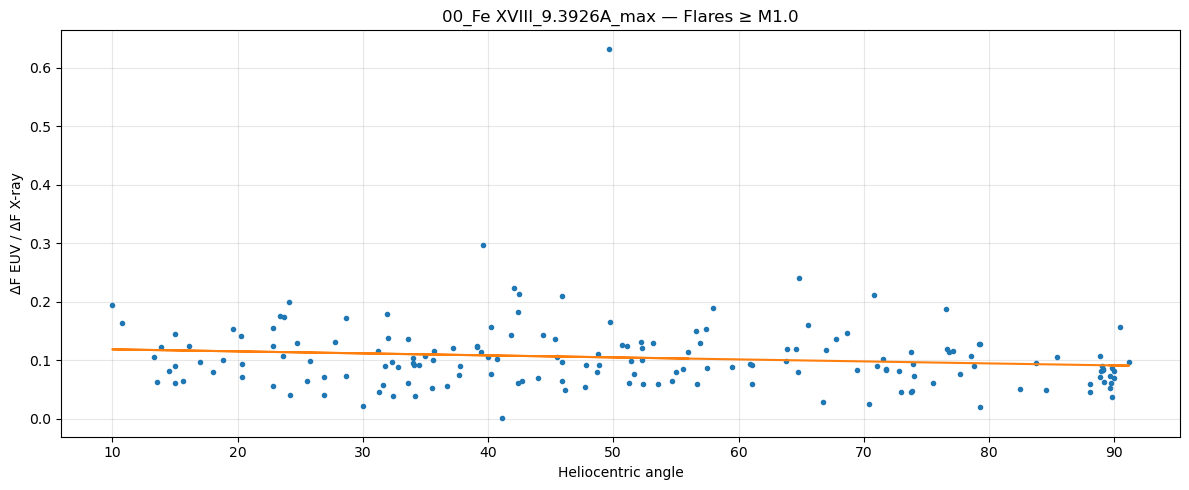

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -1.8e-05
r-value = -0.076704
p-value = 0.318695


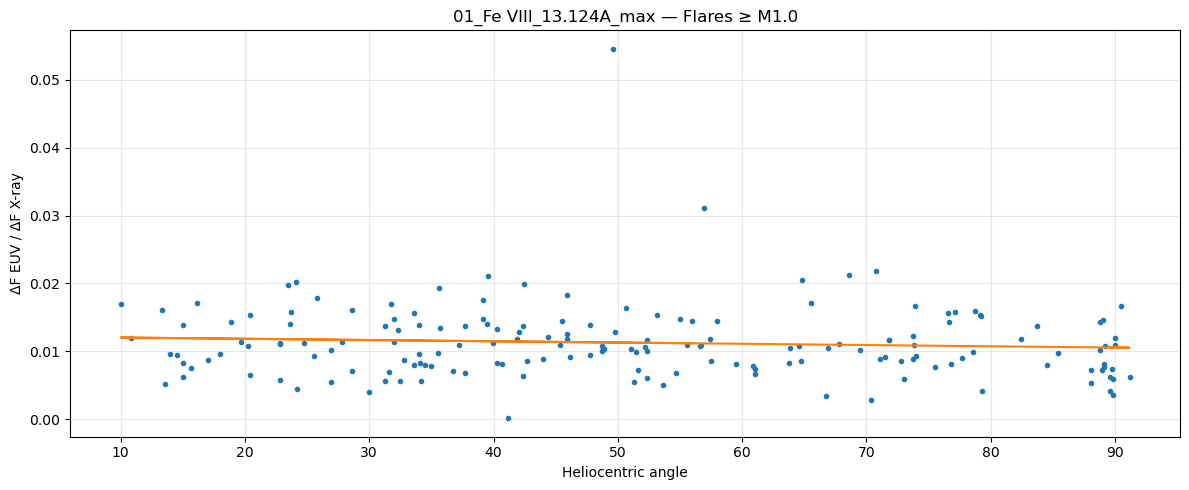

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.001018
r-value = -0.302578
p-value = 5.8e-05


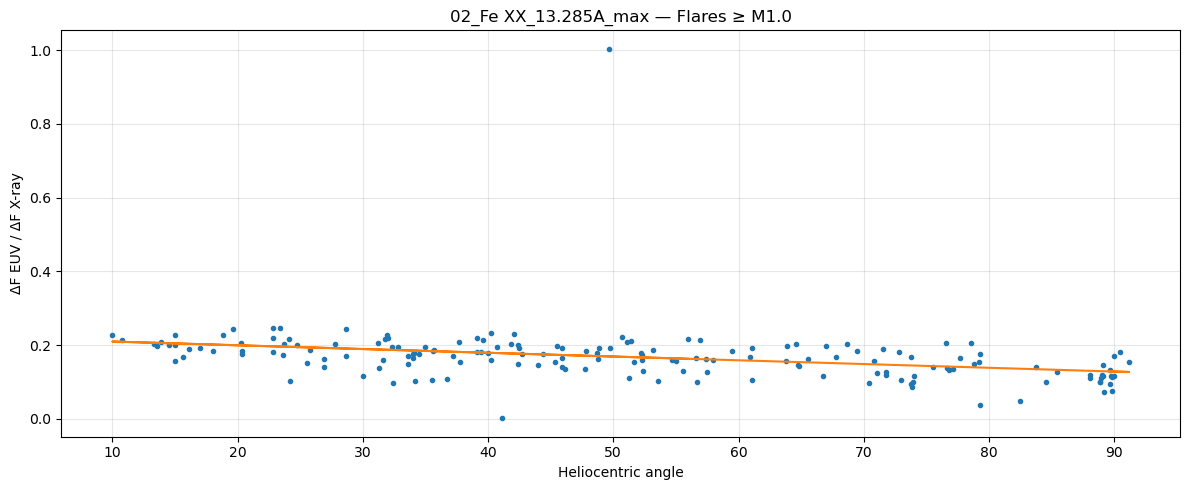

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000188
r-value = -0.107313
p-value = 0.162399


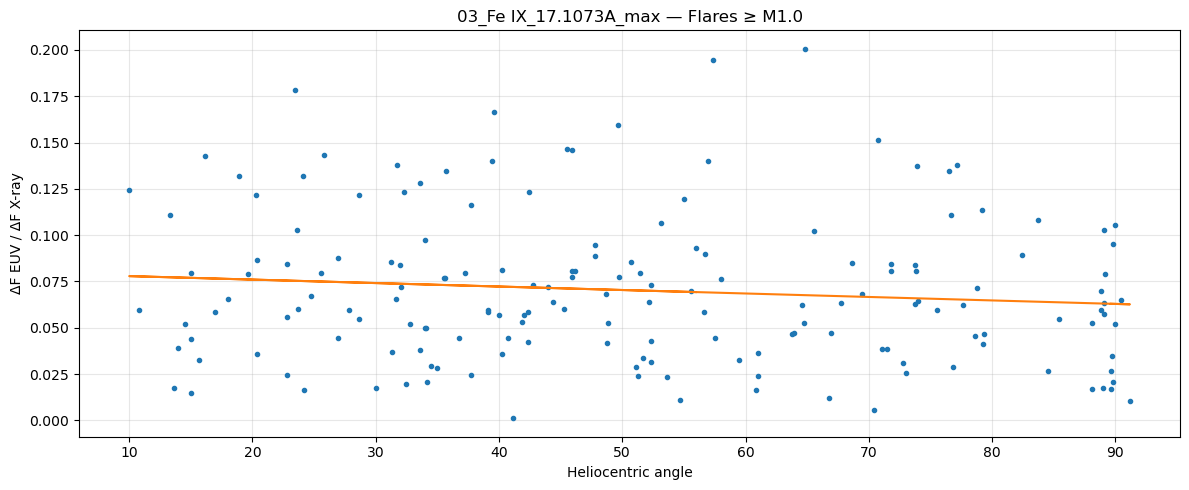

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -7.1e-05
r-value = -0.070077
p-value = 0.362412


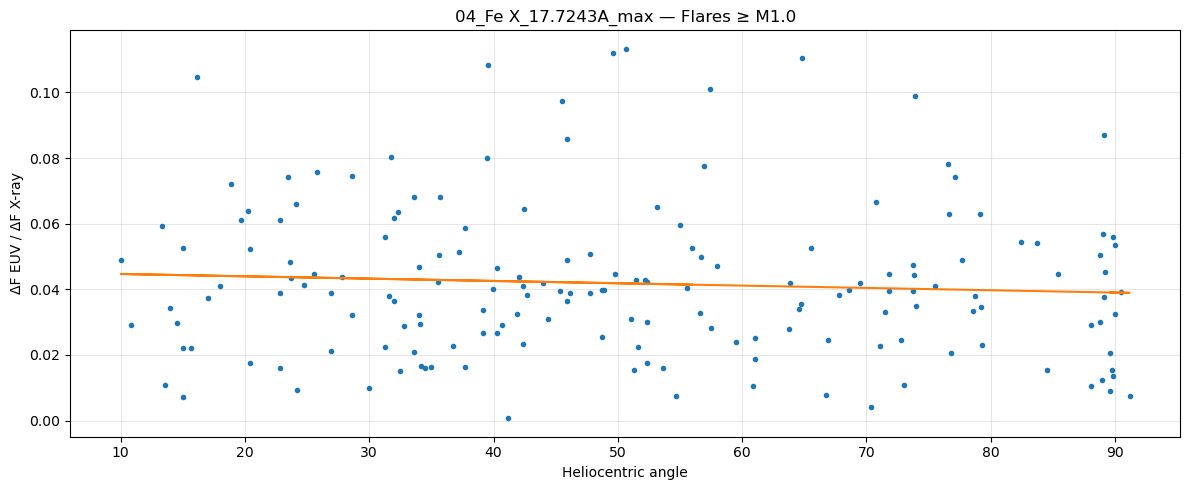

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -6.3e-05
r-value = -0.049514
p-value = 0.520147


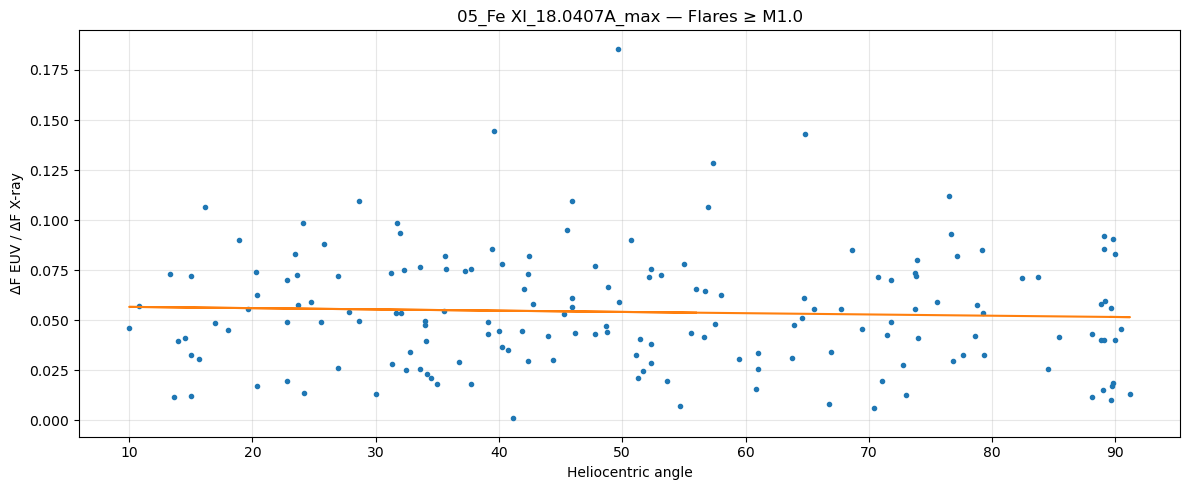

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -1.9e-05
r-value = -0.019107
p-value = 0.804102


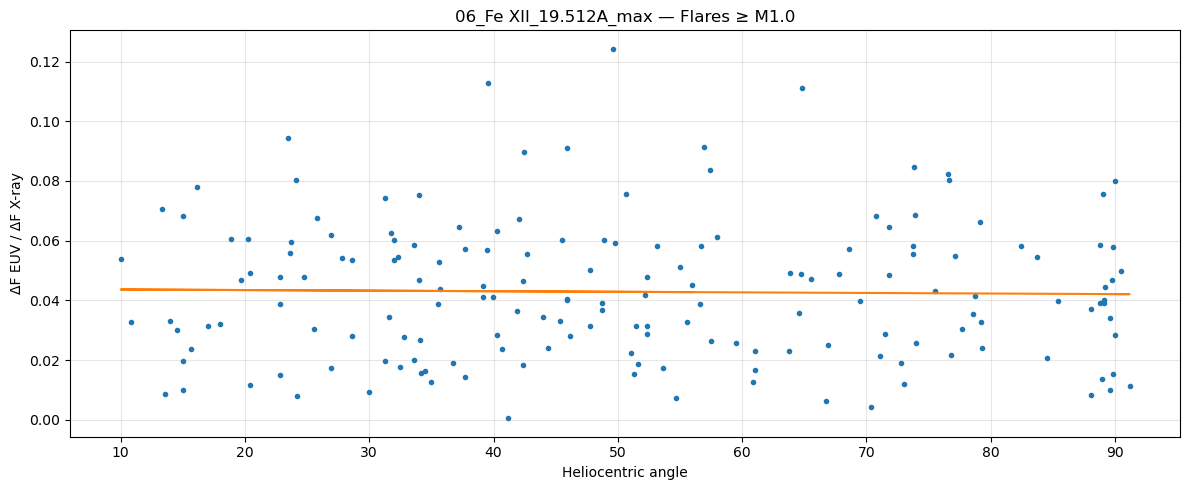

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = 3.9e-05
r-value = 0.048725
p-value = 0.526823


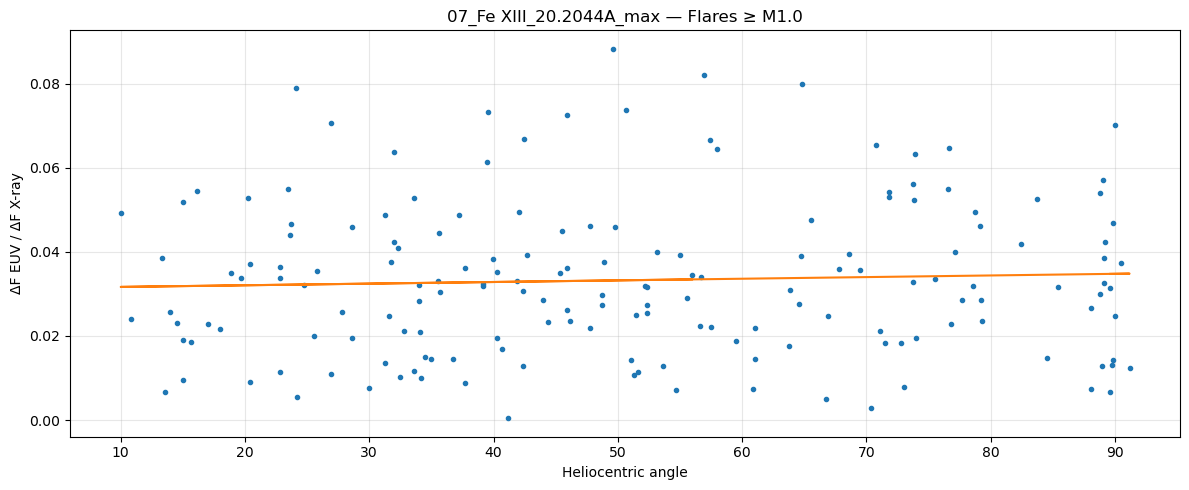

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -3.3e-05
r-value = -0.033471
p-value = 0.663847


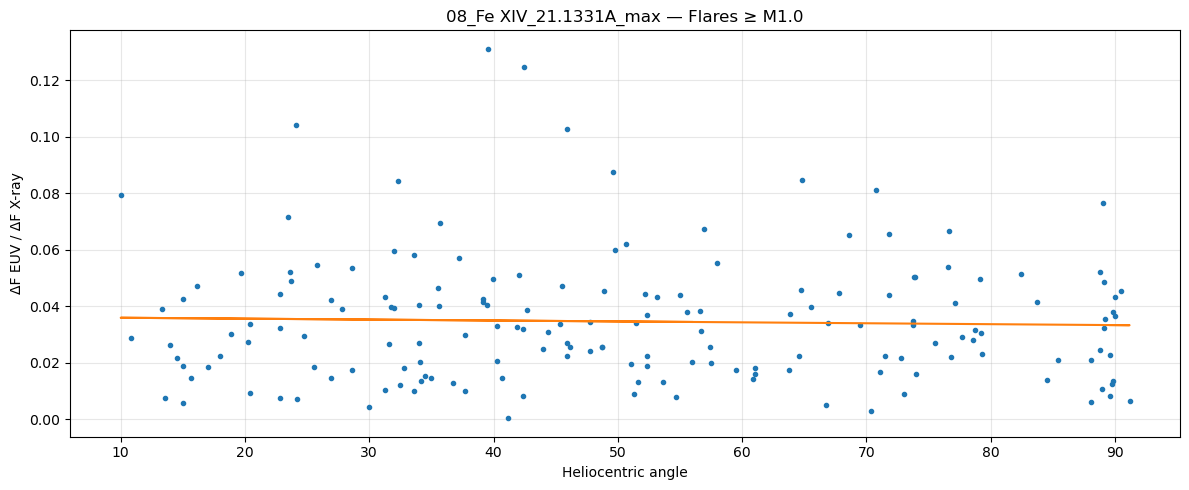

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000606
r-value = -0.309666
p-value = 3.8e-05


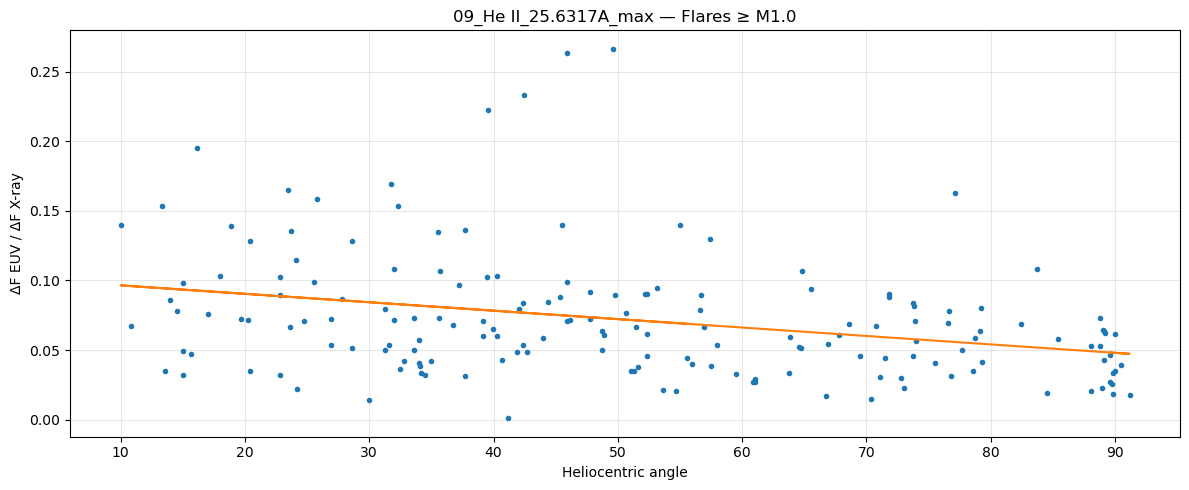

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000793
r-value = -0.144813
p-value = 0.05879


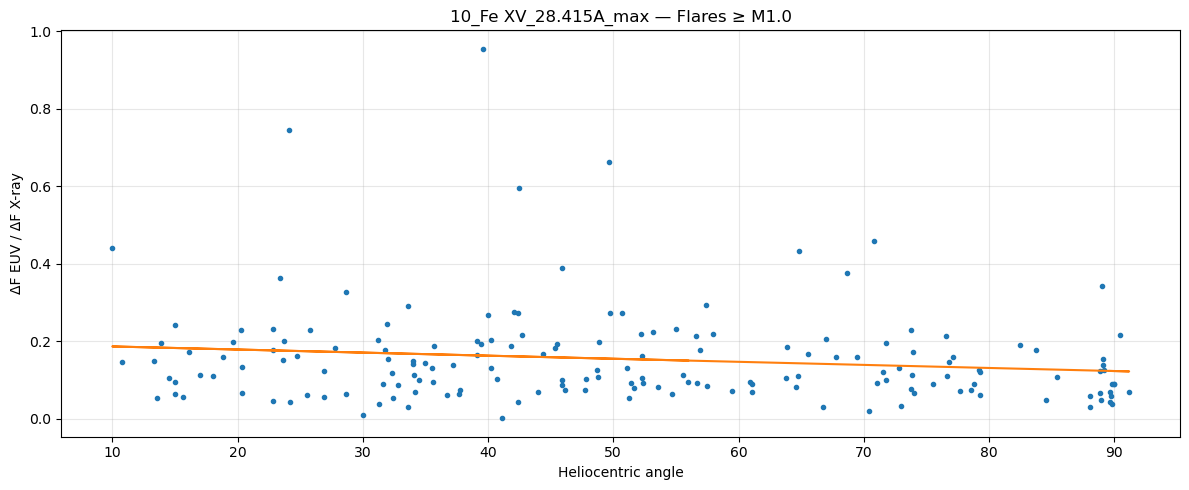

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.019319
r-value = -0.363752
p-value = 1e-06


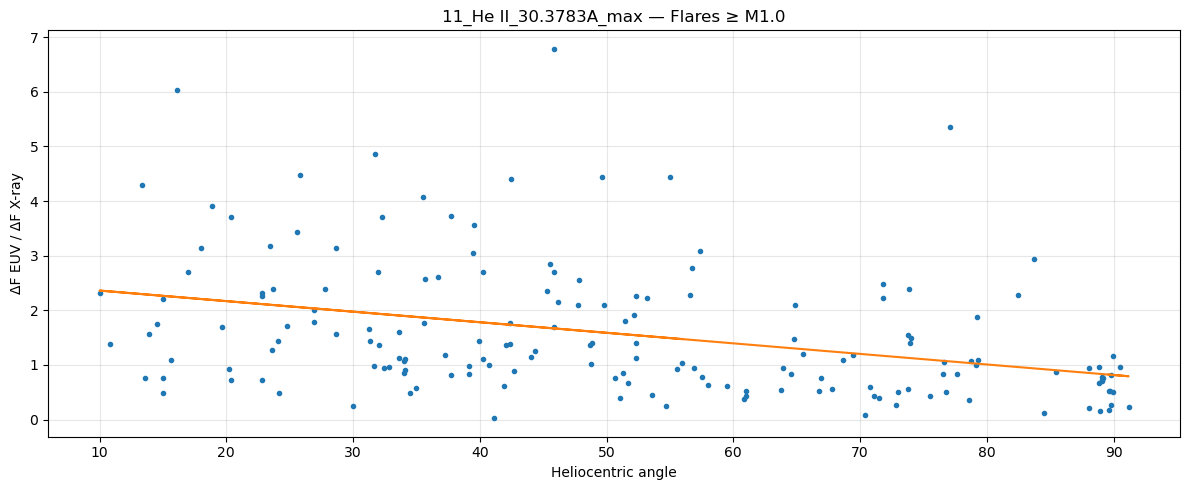

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = 0.000626
r-value = 0.041053
p-value = 0.848948


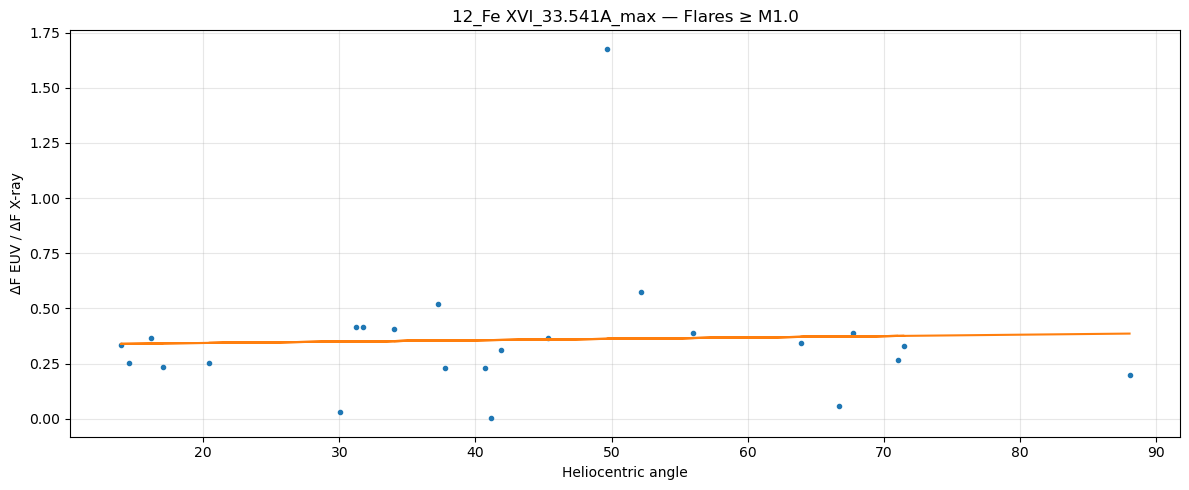

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = 0.000232
r-value = 0.029153
p-value = 0.892436


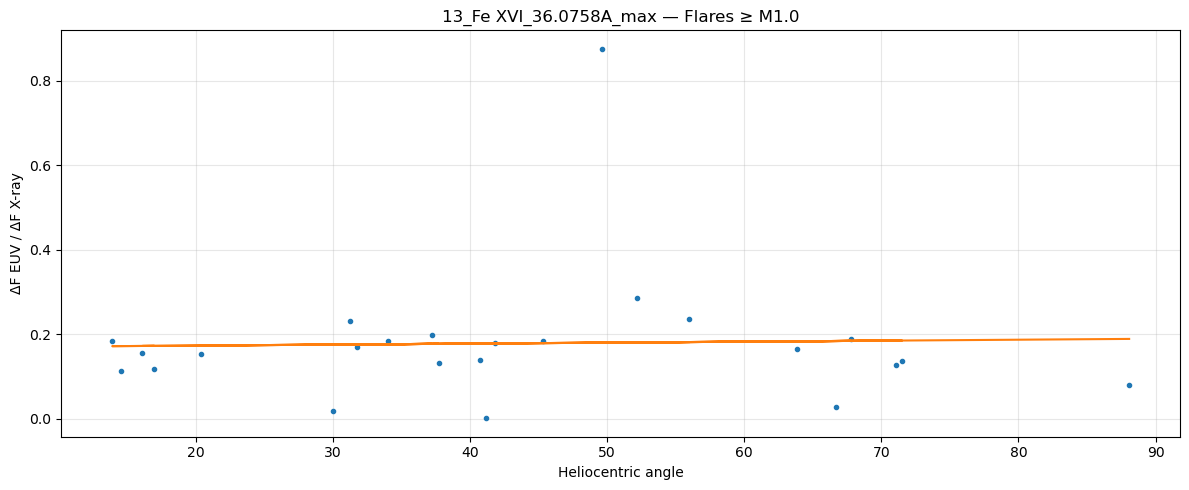

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -8e-05
r-value = -0.028371
p-value = 0.895304


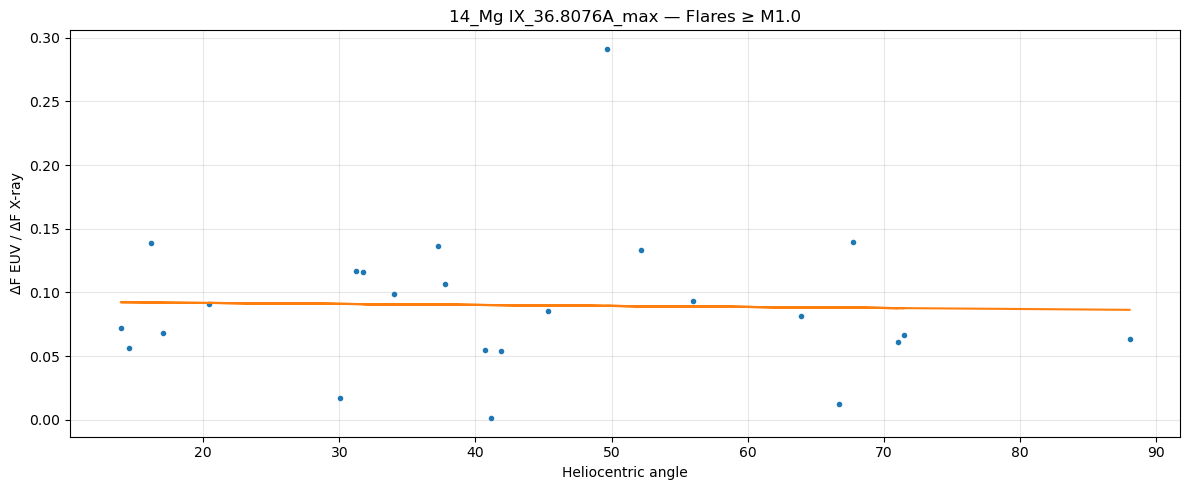

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -3e-06
r-value = -0.007196
p-value = 0.973378


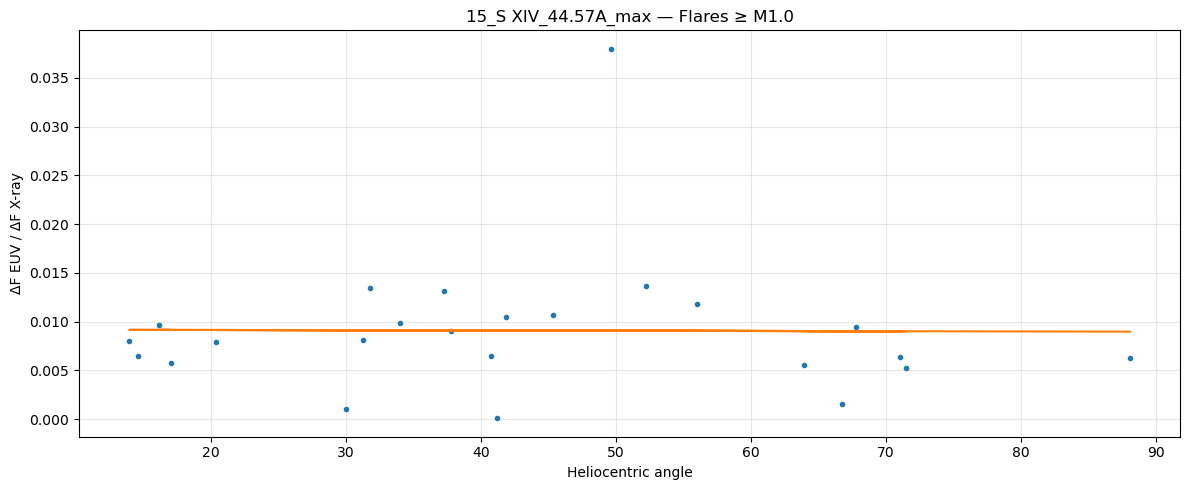

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000831
r-value = -0.437936
p-value = 0.032326


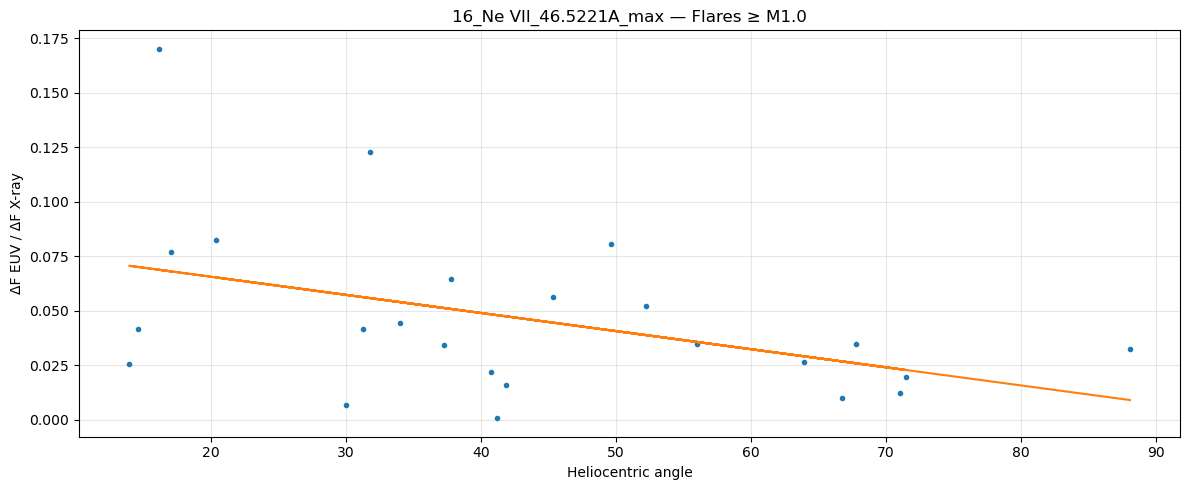

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000235
r-value = -0.097989
p-value = 0.648736


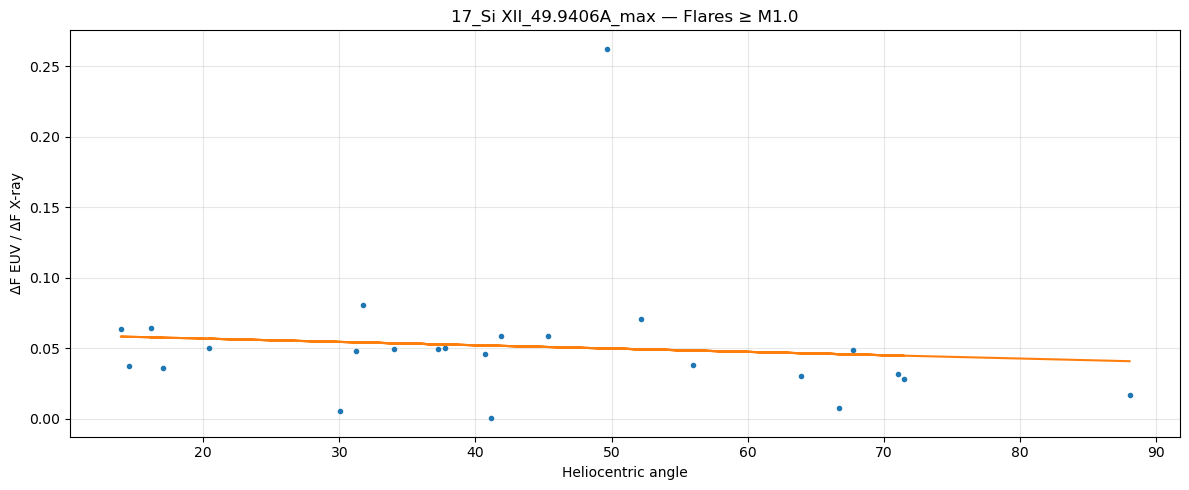

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -4.1e-05
r-value = -0.038158
p-value = 0.859491


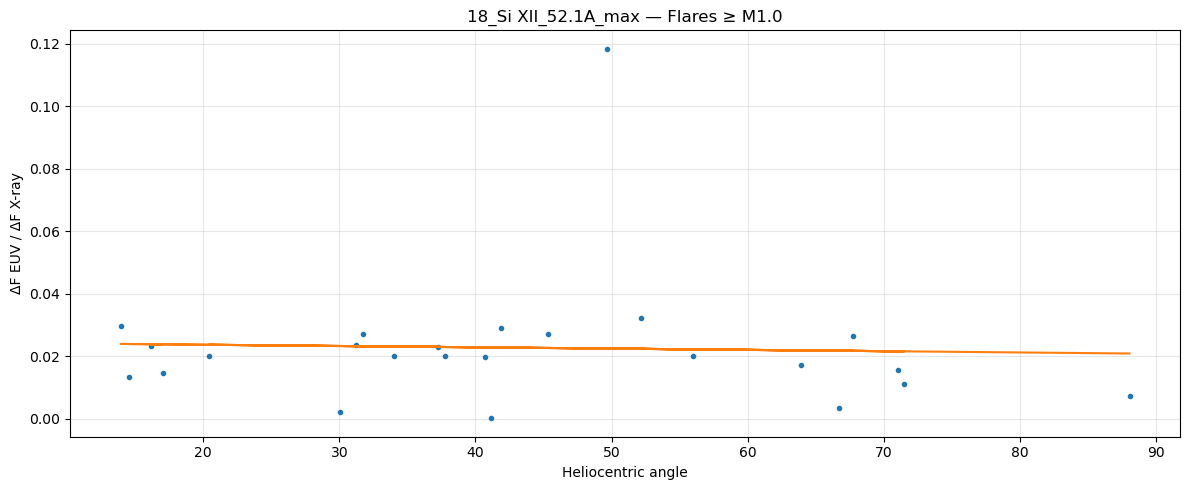

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.0002
r-value = -0.454944
p-value = 0.025503


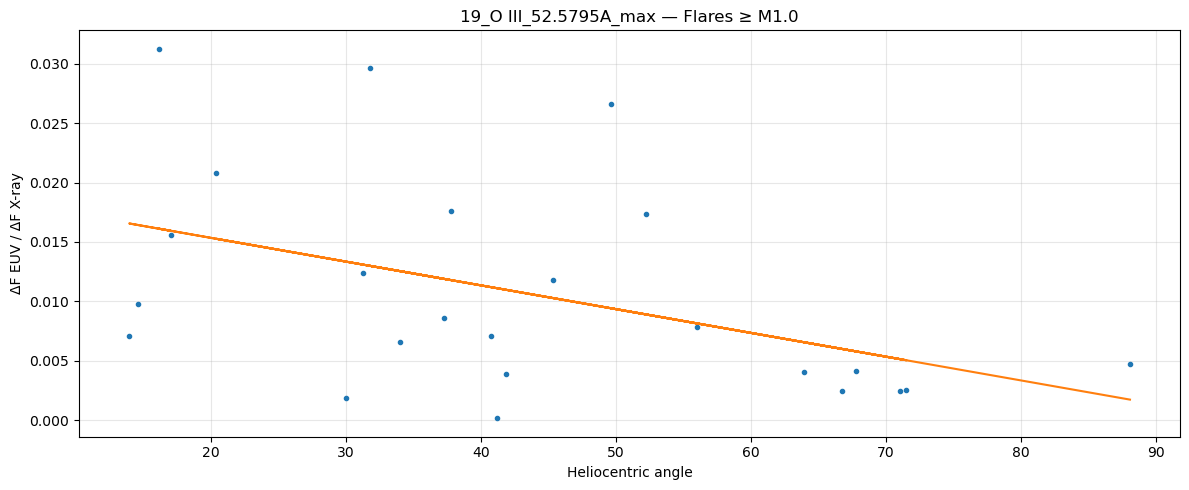

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.00062
r-value = -0.436978
p-value = 0.03275


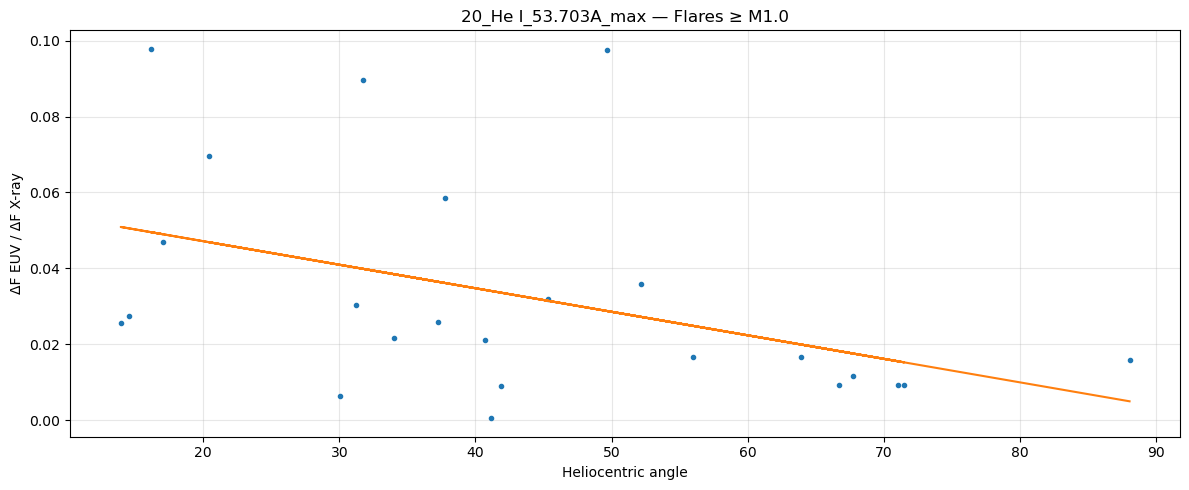

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.001711
r-value = -0.499907
p-value = 0.012865


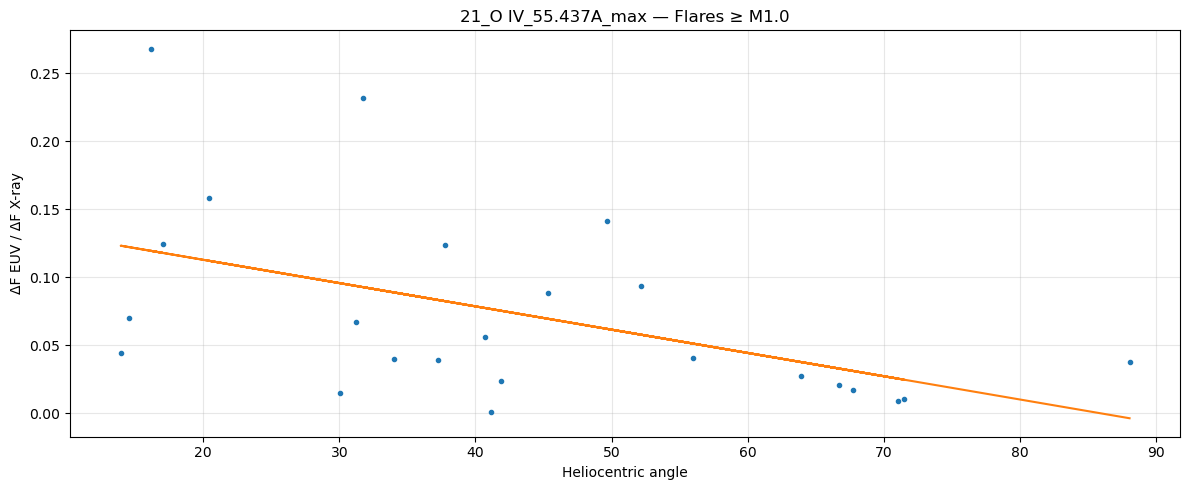

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -1.2e-05
r-value = -0.035027
p-value = 0.870924


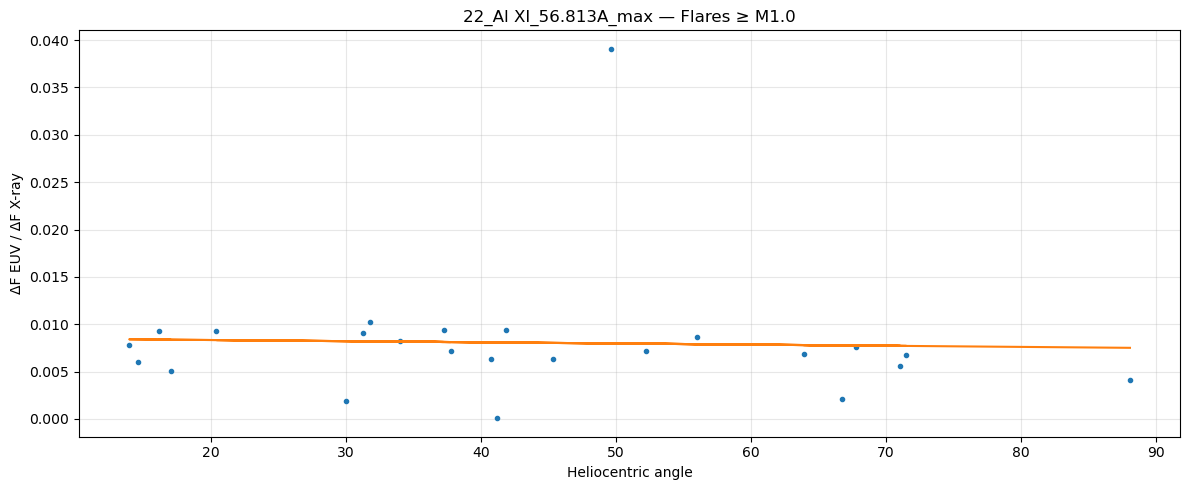

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.002312
r-value = -0.241117
p-value = 0.256369


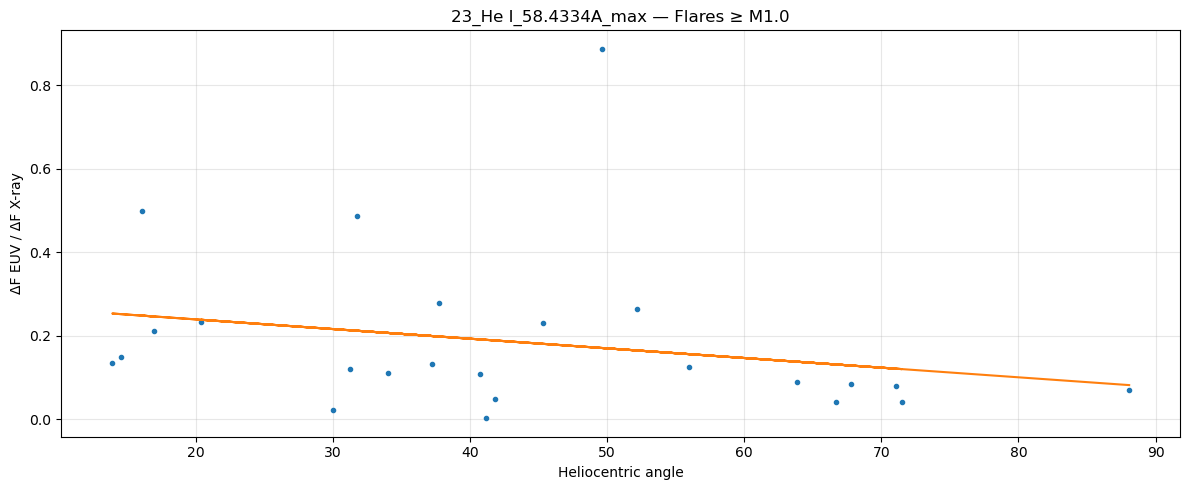

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = 2.4e-05
r-value = 0.05129
p-value = 0.811871


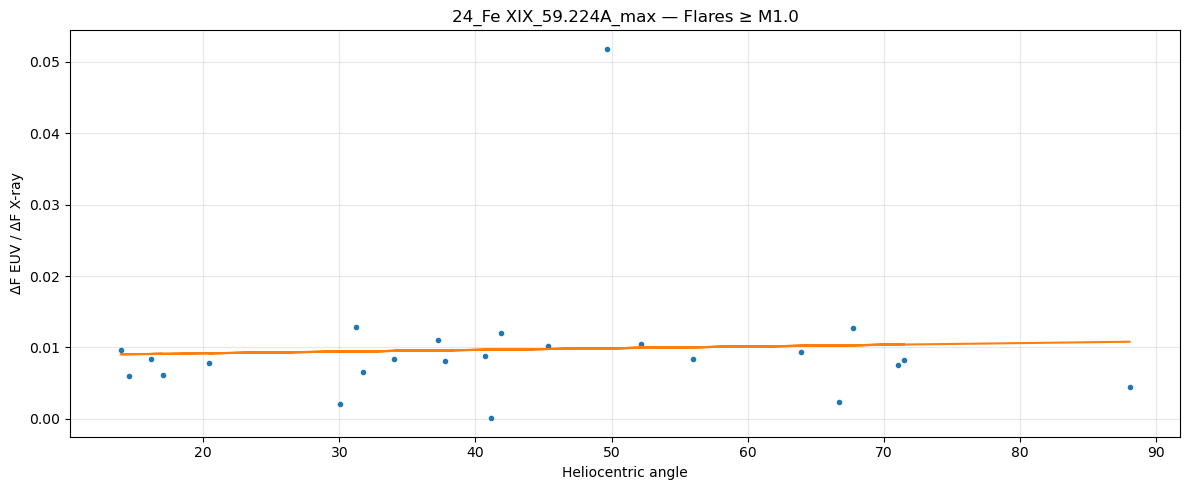

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000361
r-value = -0.462345
p-value = 0.022921


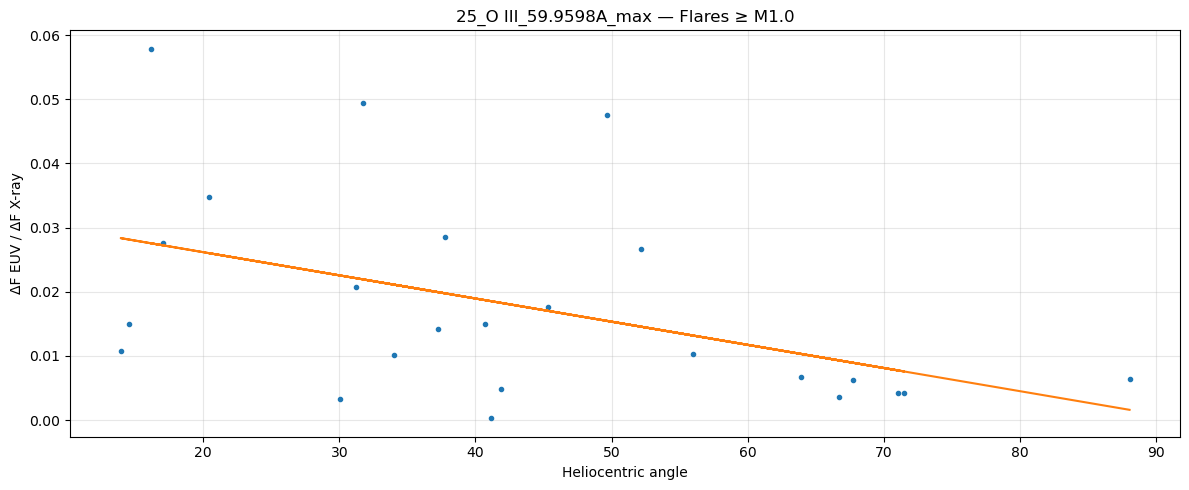

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000454
r-value = -0.2563
p-value = 0.226702


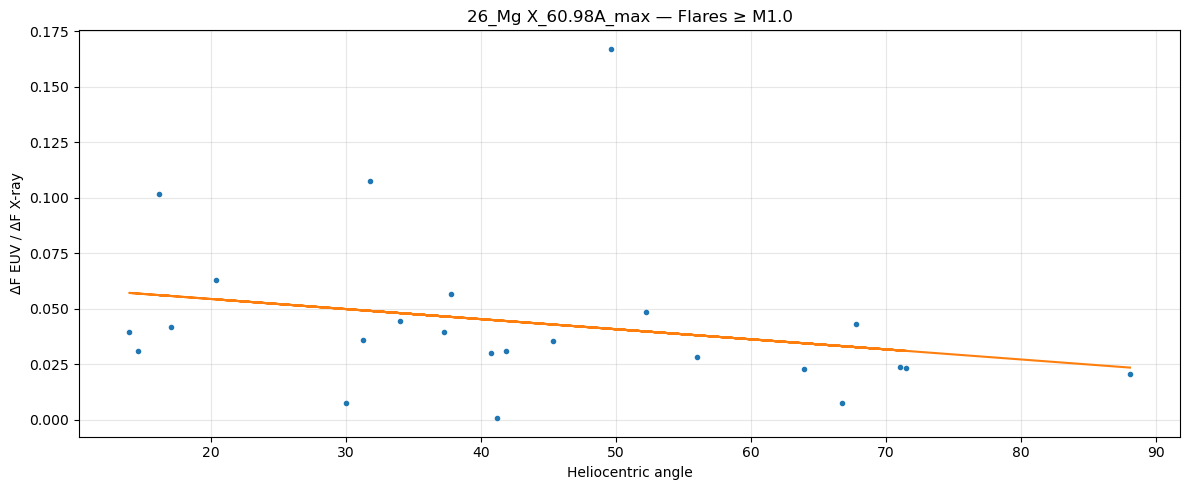

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000291
r-value = -0.274899
p-value = 0.193585


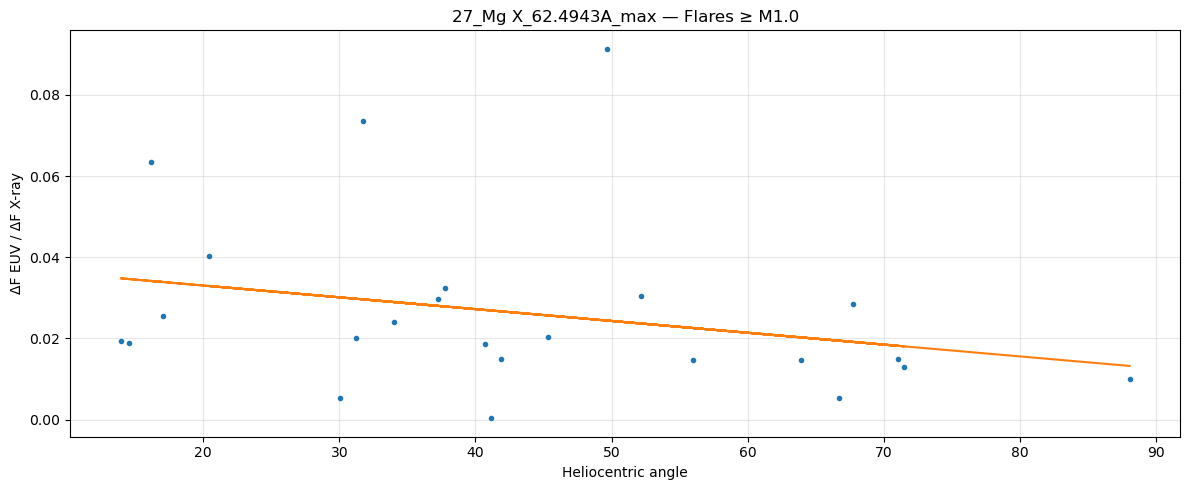

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.003206
r-value = -0.461564
p-value = 0.023183


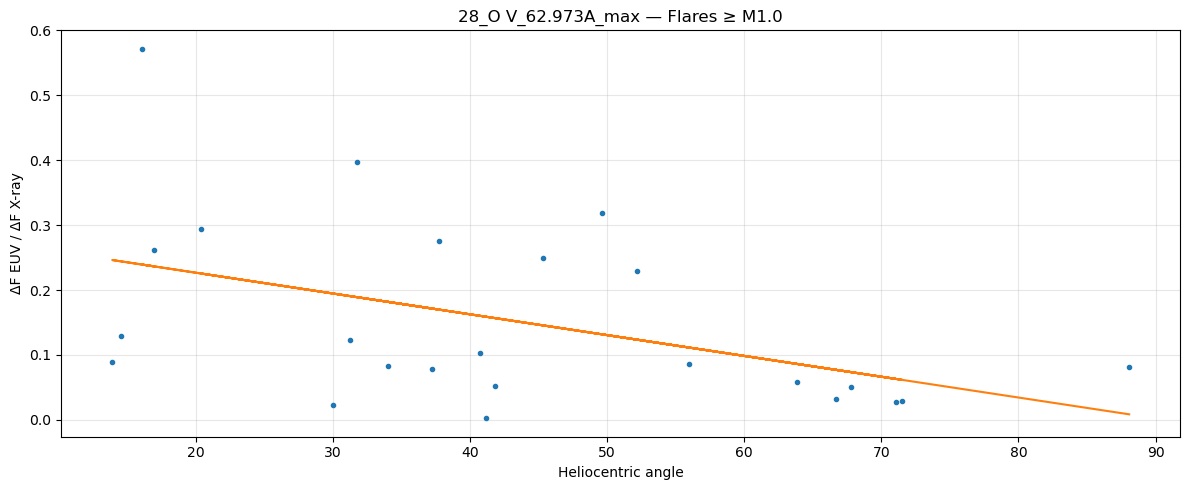

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -2e-05
r-value = -0.051987
p-value = 0.809362


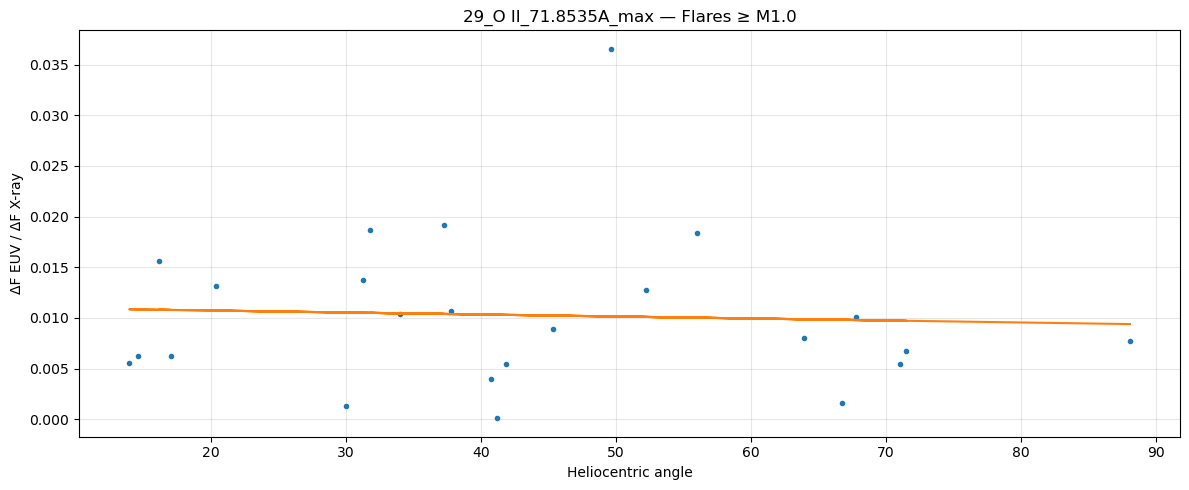

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = 4.1e-05
r-value = 0.112401
p-value = 0.601033


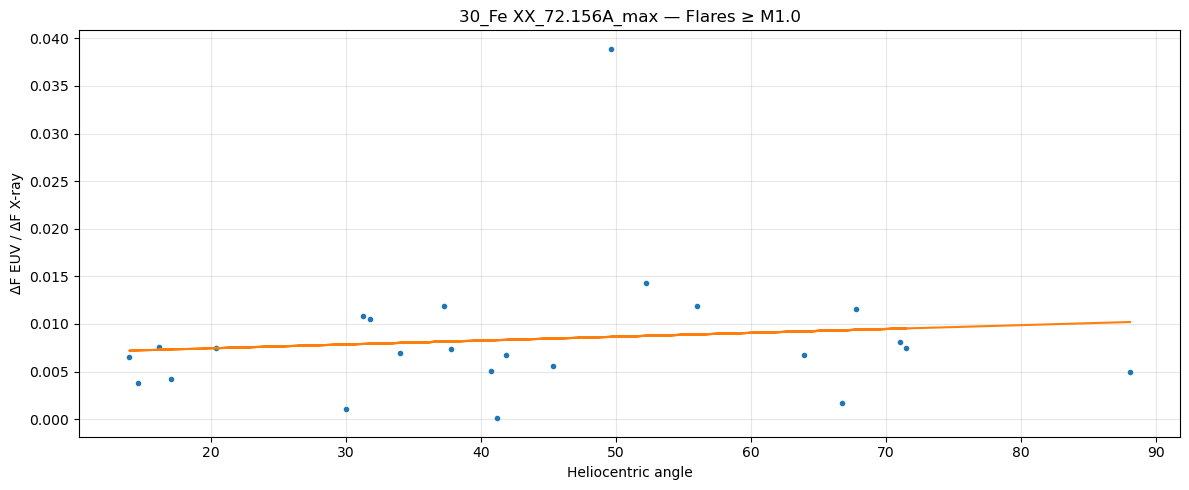

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000372
r-value = -0.255832
p-value = 0.227581


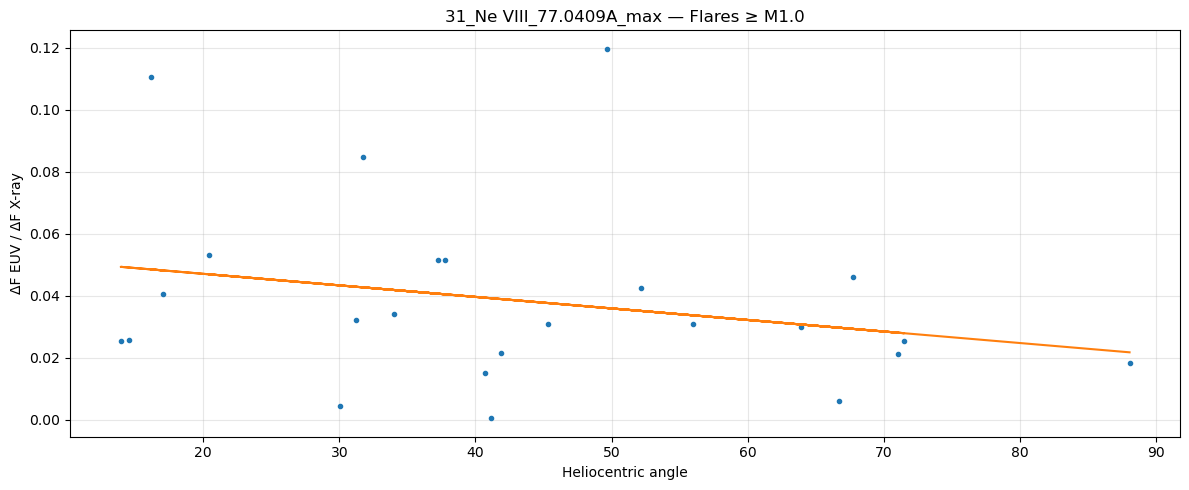

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.00158
r-value = -0.444967
p-value = 0.029348


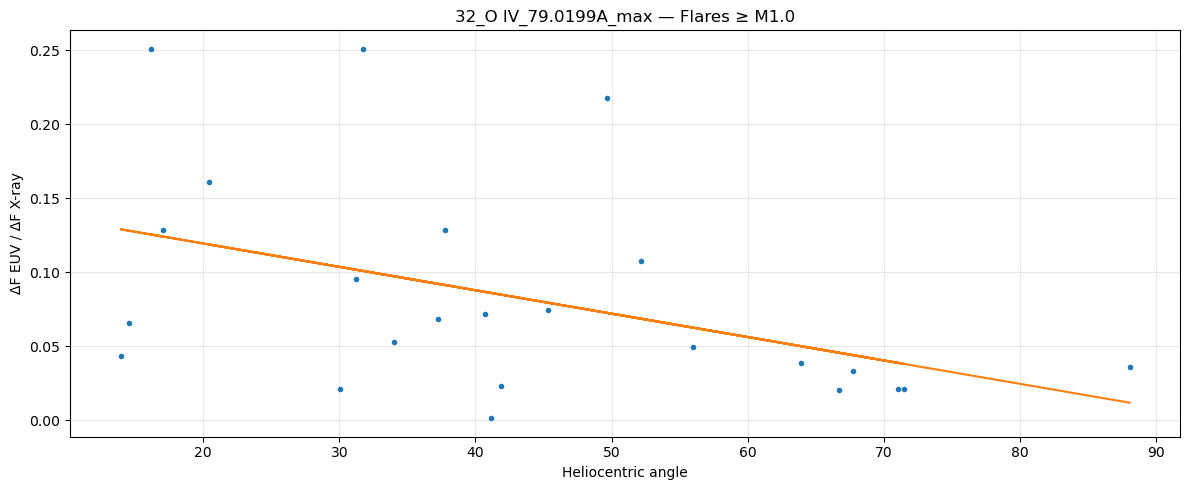

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.003902
r-value = -0.478314
p-value = 0.018066


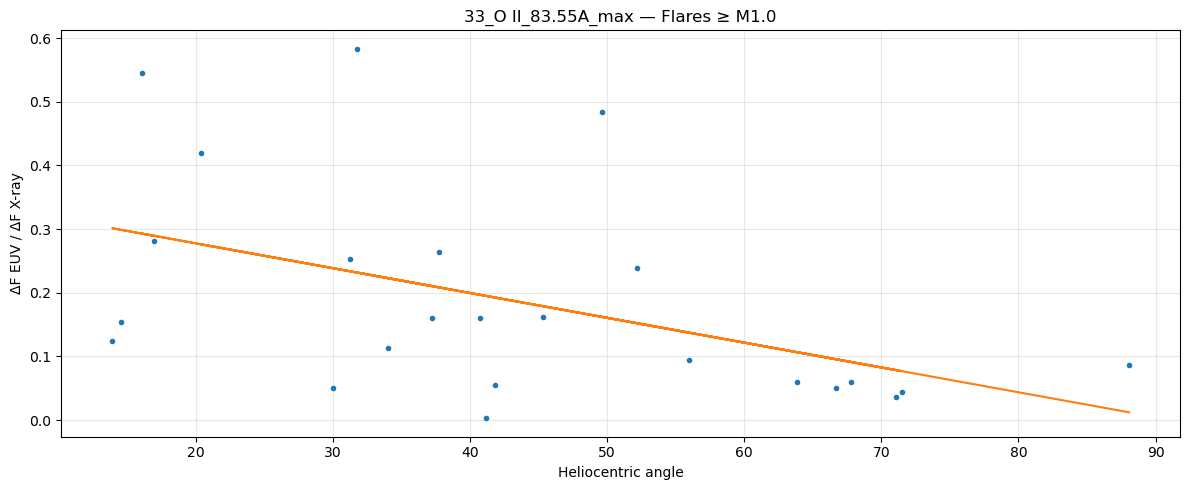

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.00044
r-value = -0.289584
p-value = 0.169891


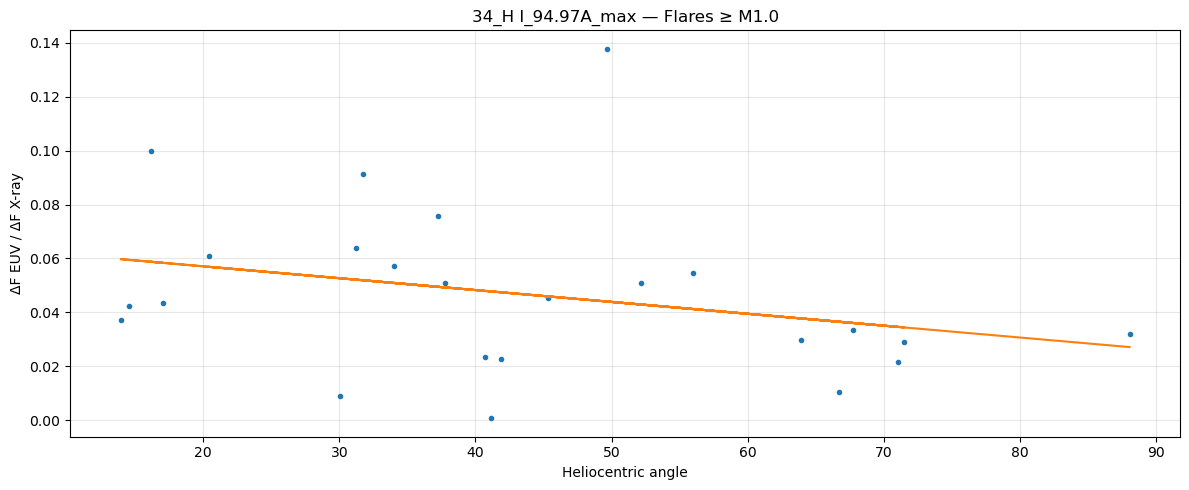

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000695
r-value = -0.331839
p-value = 0.113158


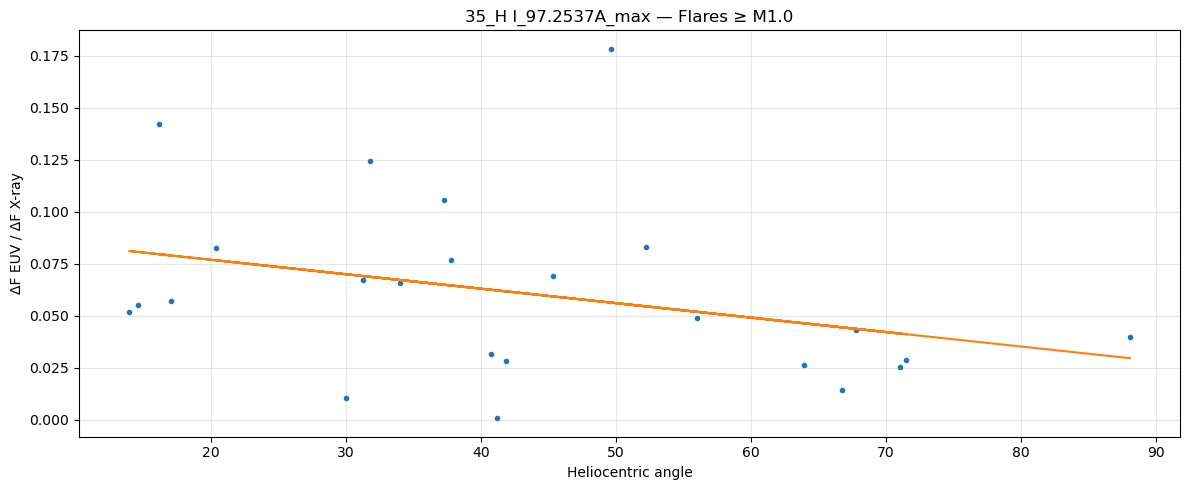

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.031423
r-value = -0.429908
p-value = 0.036015


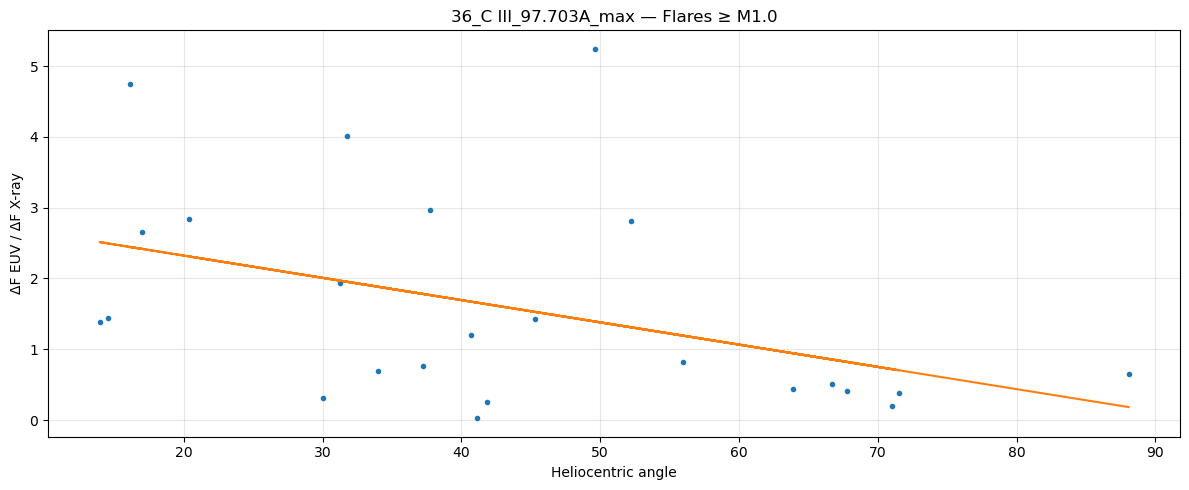

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.002629
r-value = -0.323808
p-value = 0.122692


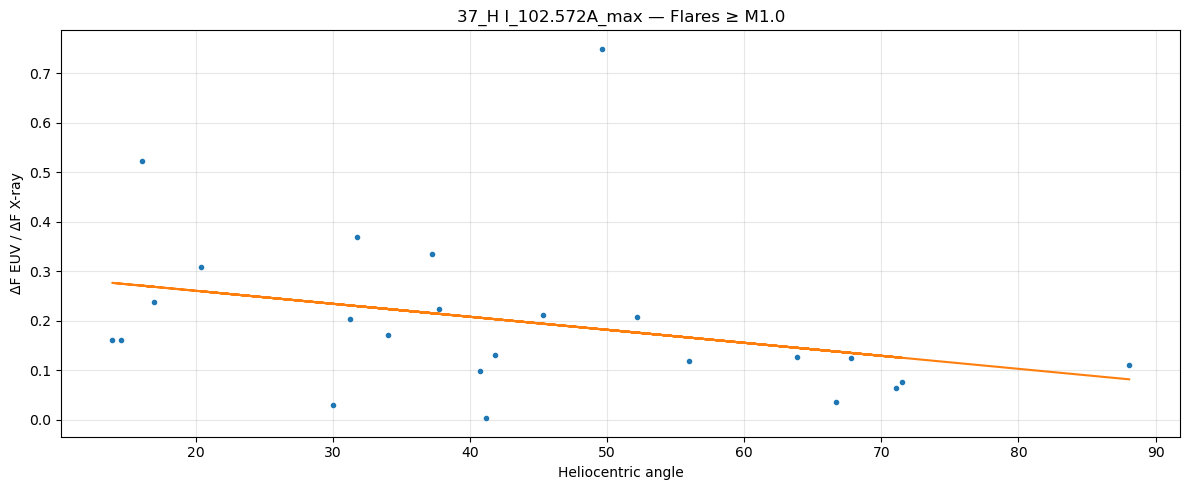

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.007973
r-value = -0.414764
p-value = 0.043877


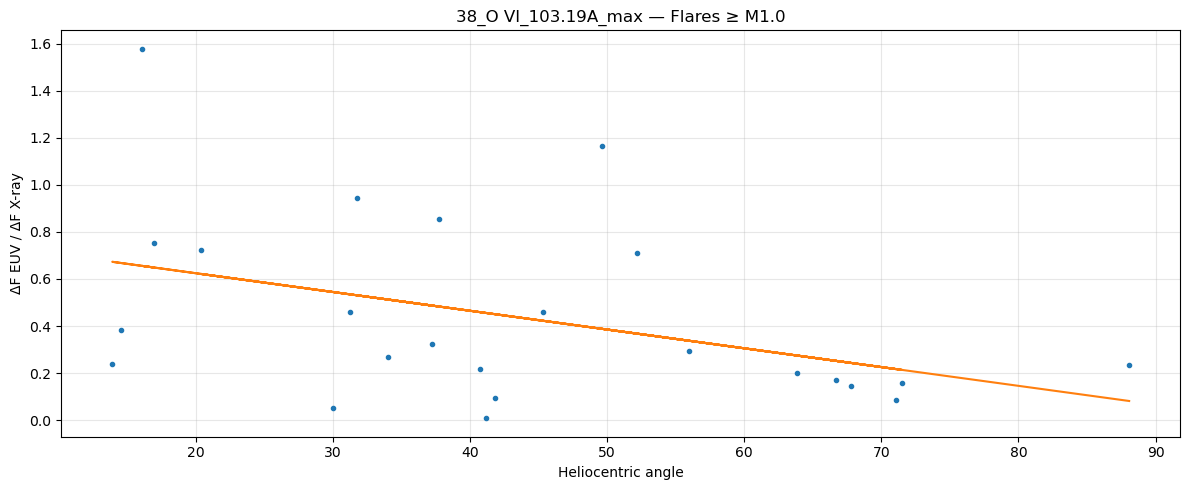

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000104
r-value = -0.088185
p-value = 0.251404


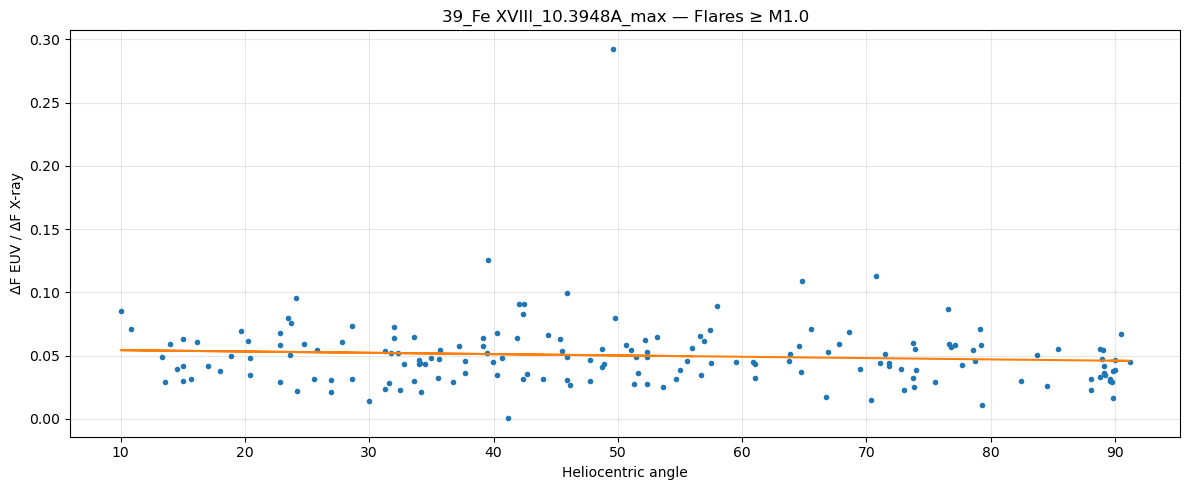

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000254
r-value = -0.111055
p-value = 0.148161


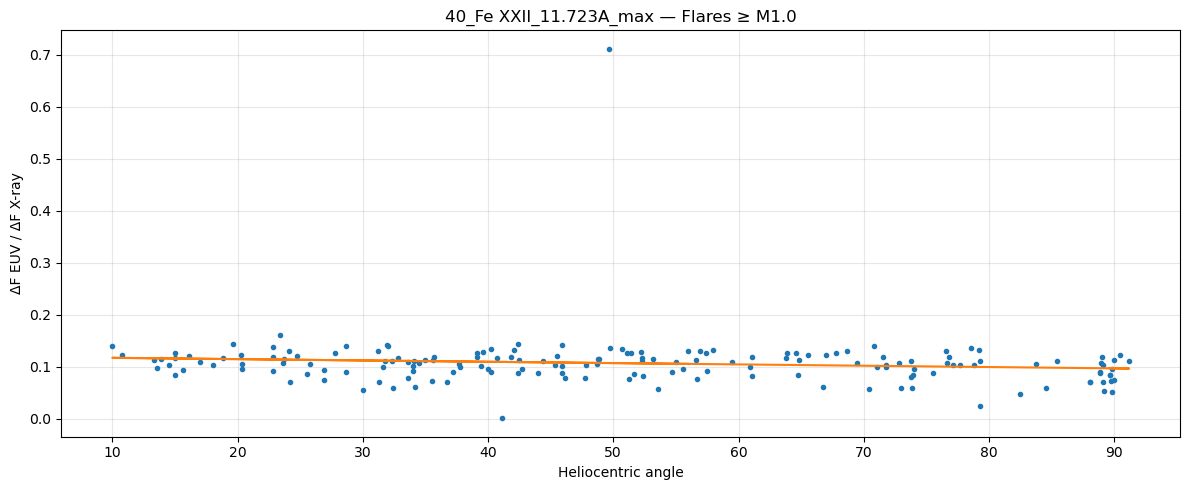

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -5e-06
r-value = -0.014013
p-value = 0.855657


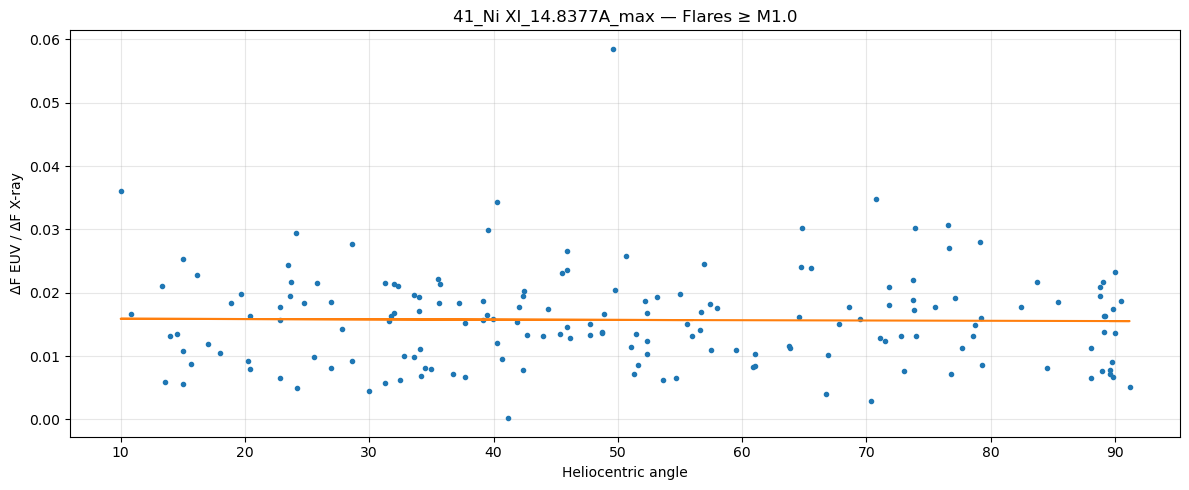

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000131
r-value = -0.095321
p-value = 0.214912


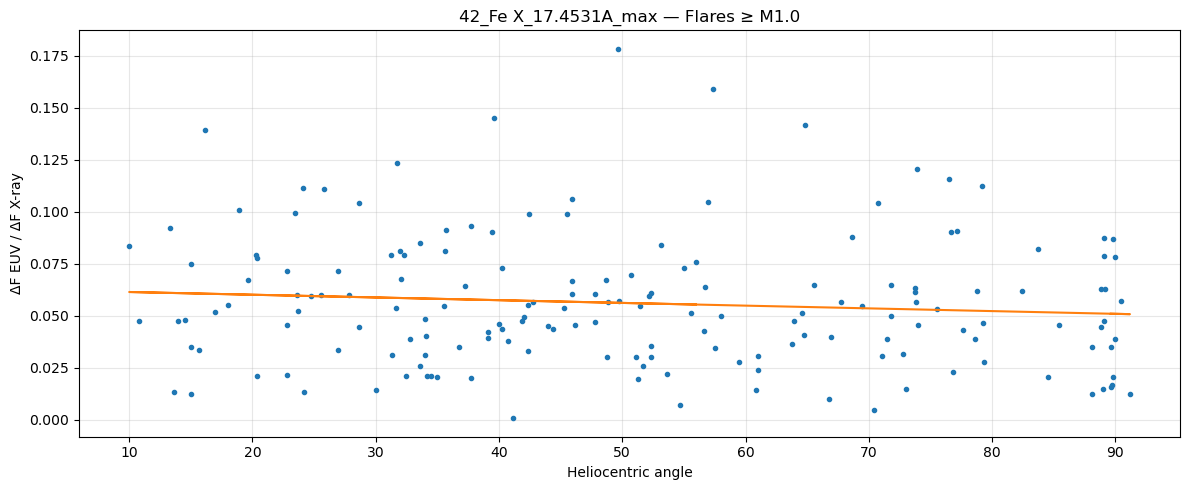

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -8.6e-05
r-value = -0.08689
p-value = 0.258458


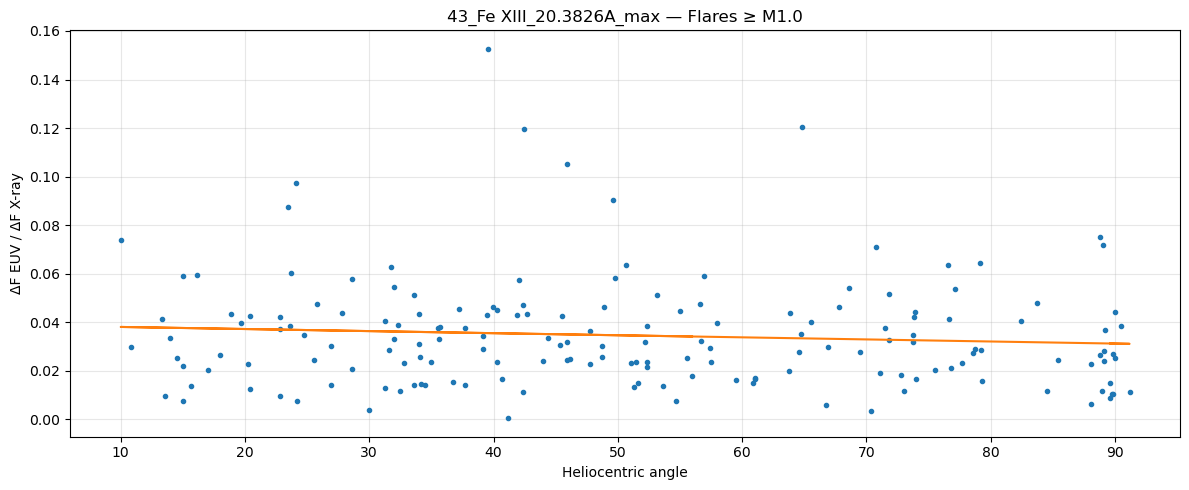

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -5.2e-05
r-value = -0.133733
p-value = 0.081194


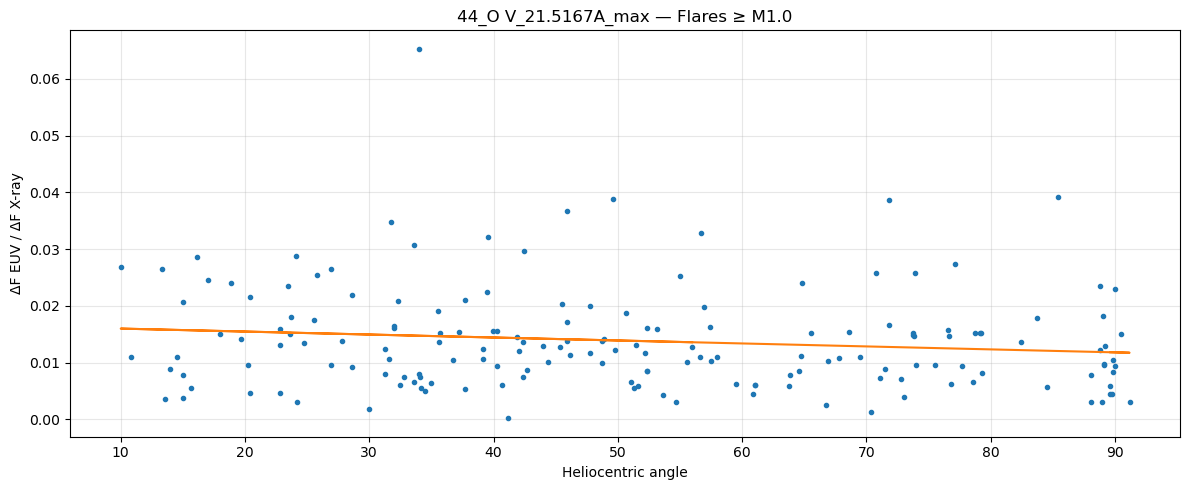

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -9e-05
r-value = -0.131917
p-value = 0.085449


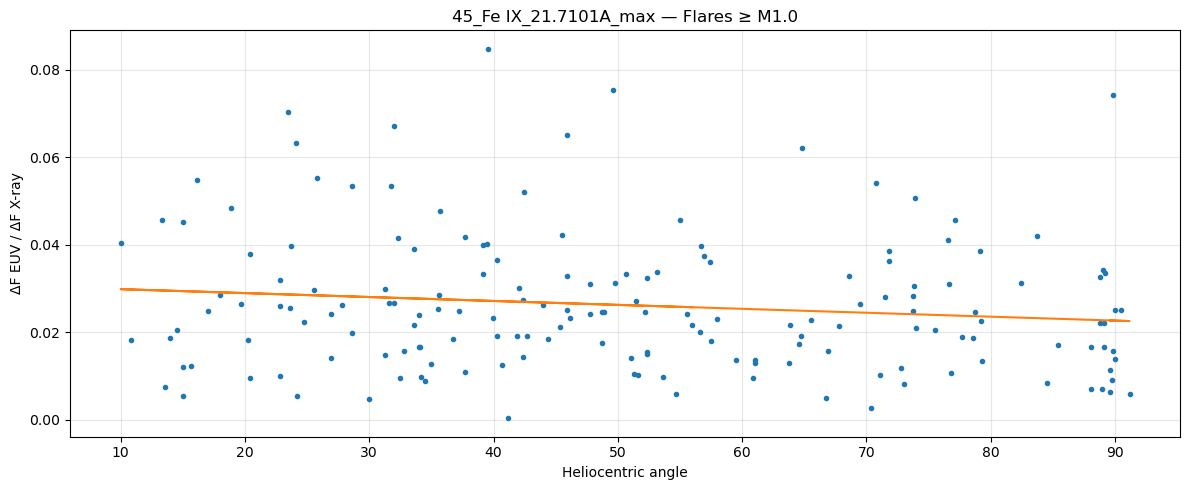

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000117
r-value = -0.13111
p-value = 0.087396


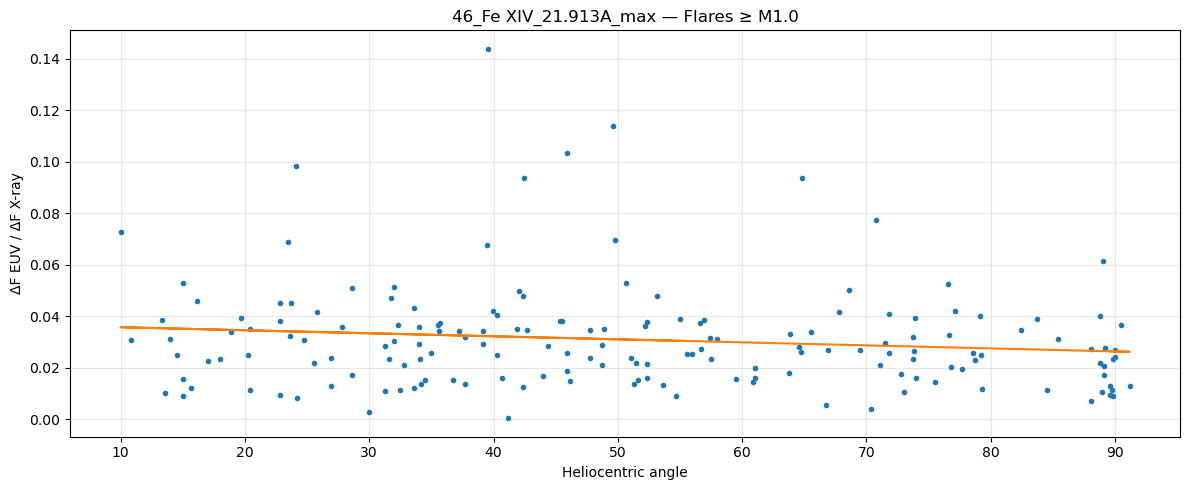

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000521
r-value = -0.157049
p-value = 0.040231


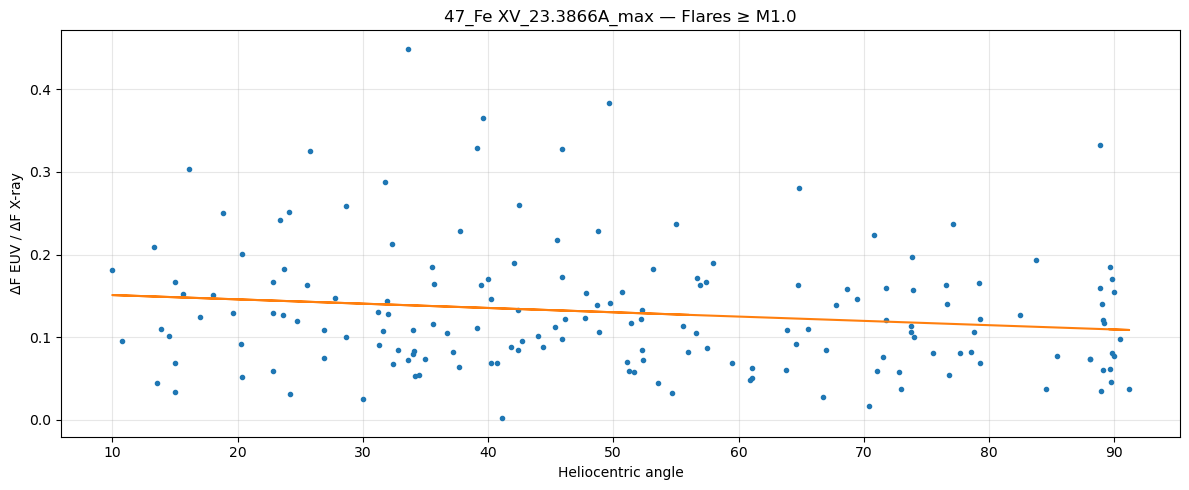

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.0
r-value = -0.000388
p-value = 0.99598


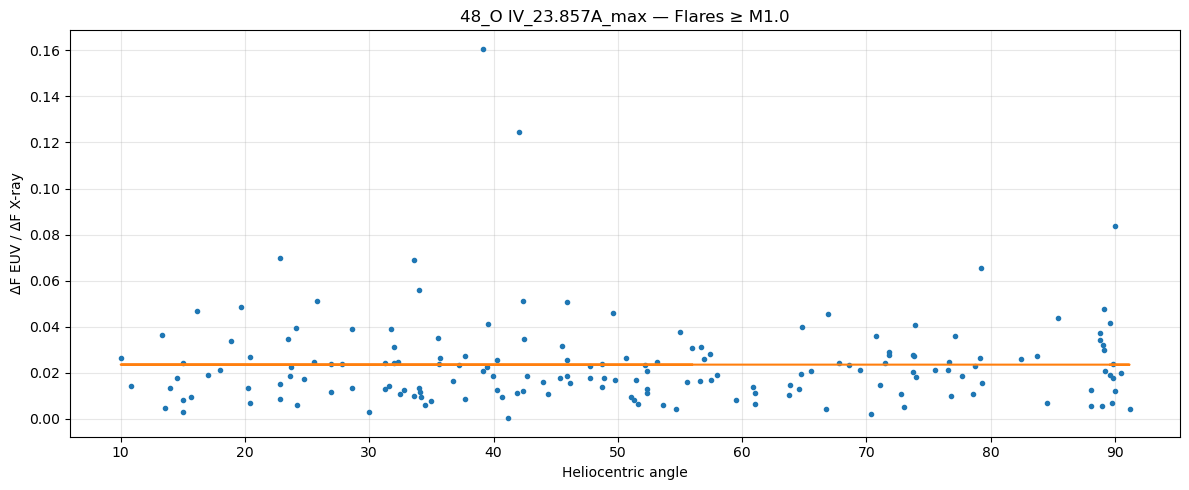

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -1e-06
r-value = -0.00058
p-value = 0.99399


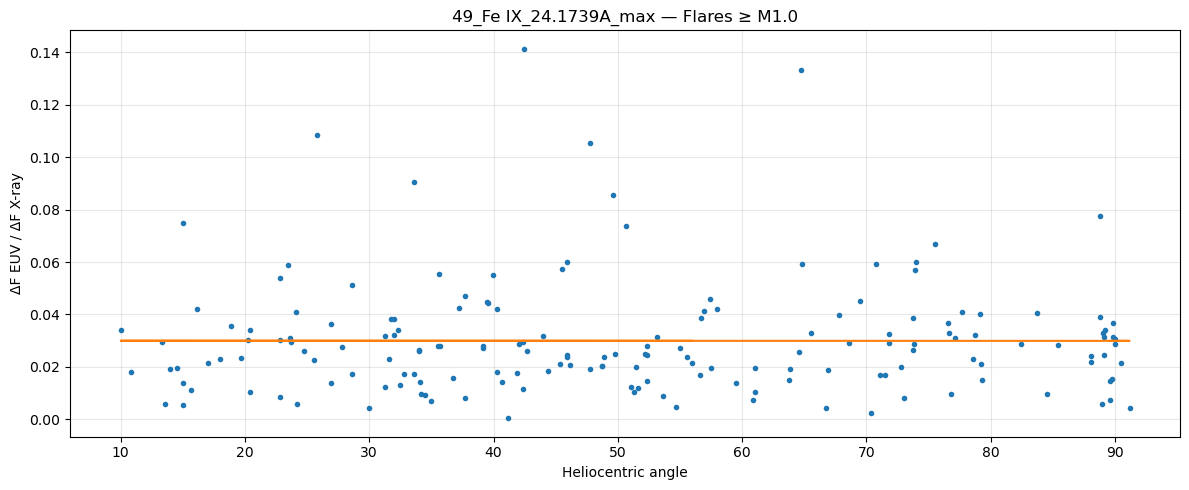

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -2e-06
r-value = -0.002456
p-value = 0.974565


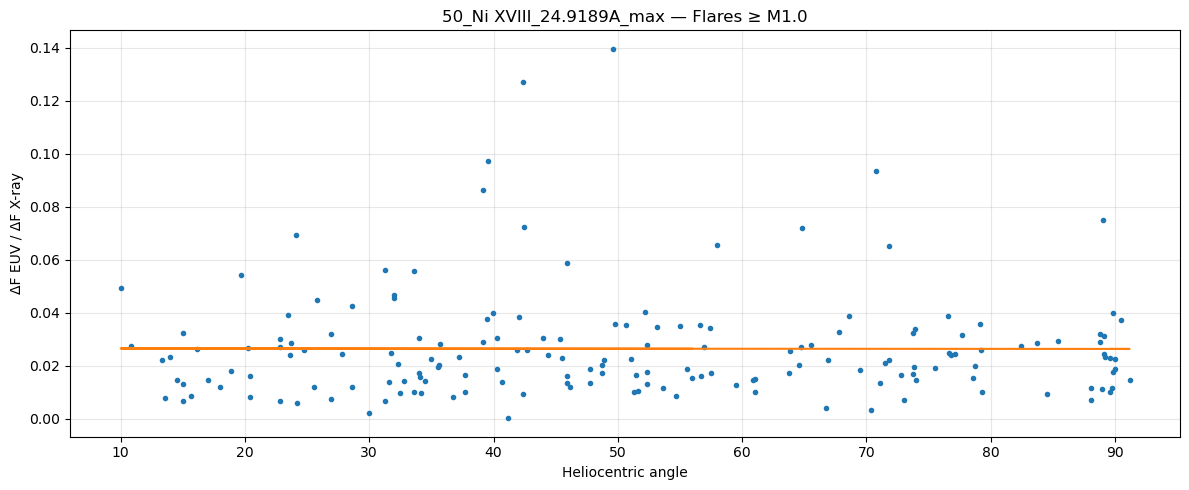

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -3.4e-05
r-value = -0.033174
p-value = 0.666658


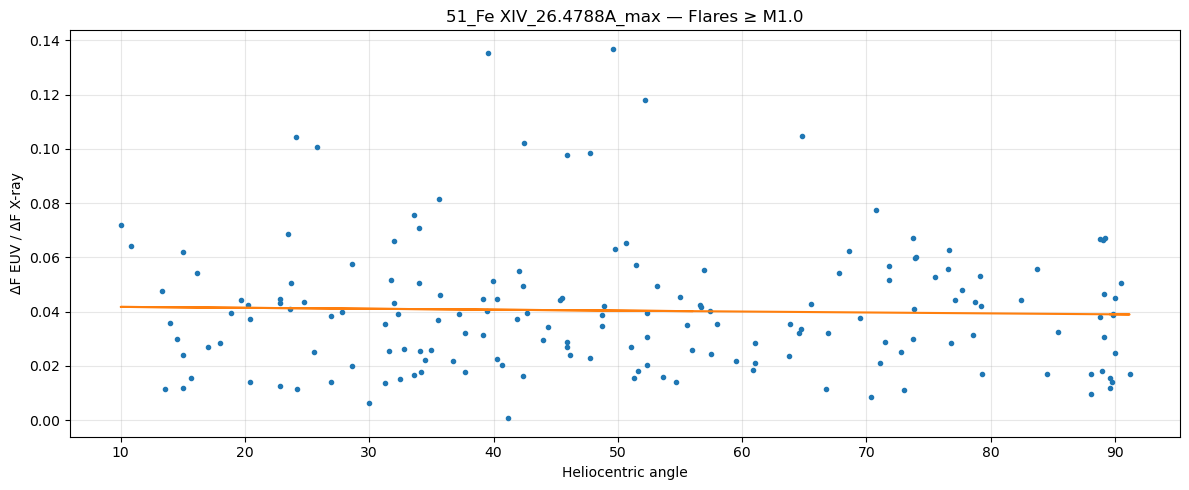

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = 2.9e-05
r-value = 0.036195
p-value = 0.63836


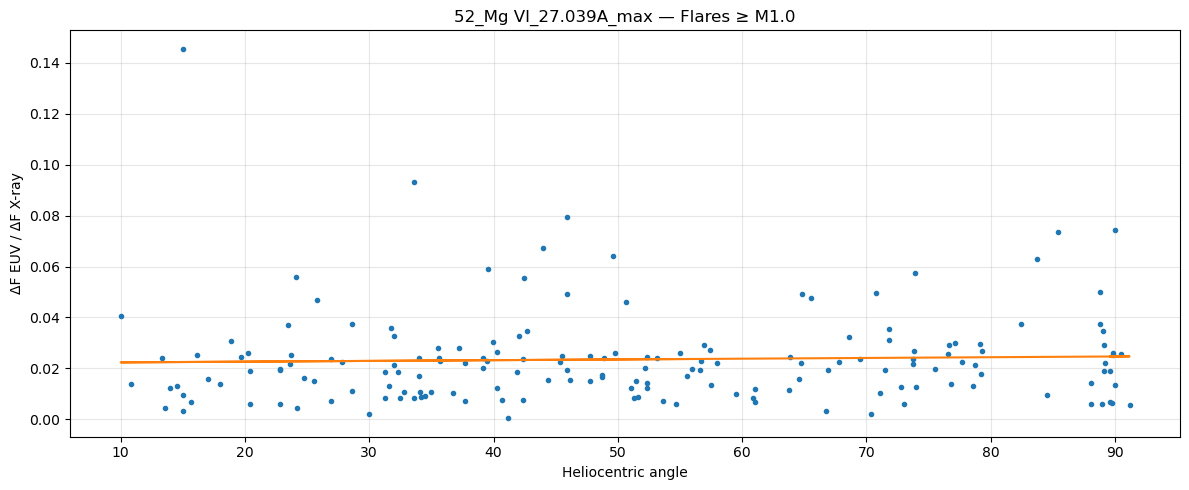

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -2.3e-05
r-value = -0.047636
p-value = 0.825065


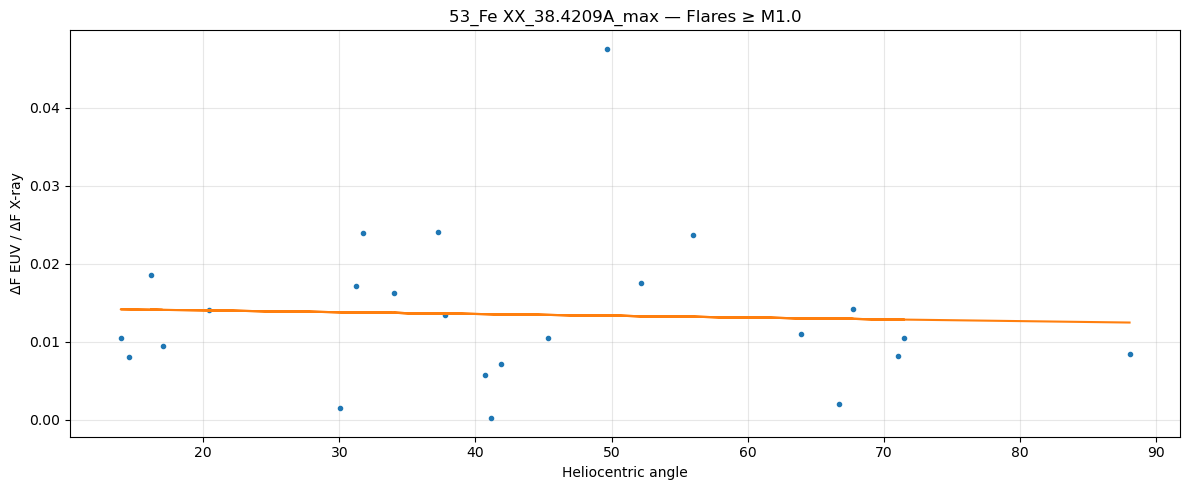

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = 2.2e-05
r-value = 0.066016
p-value = 0.759239


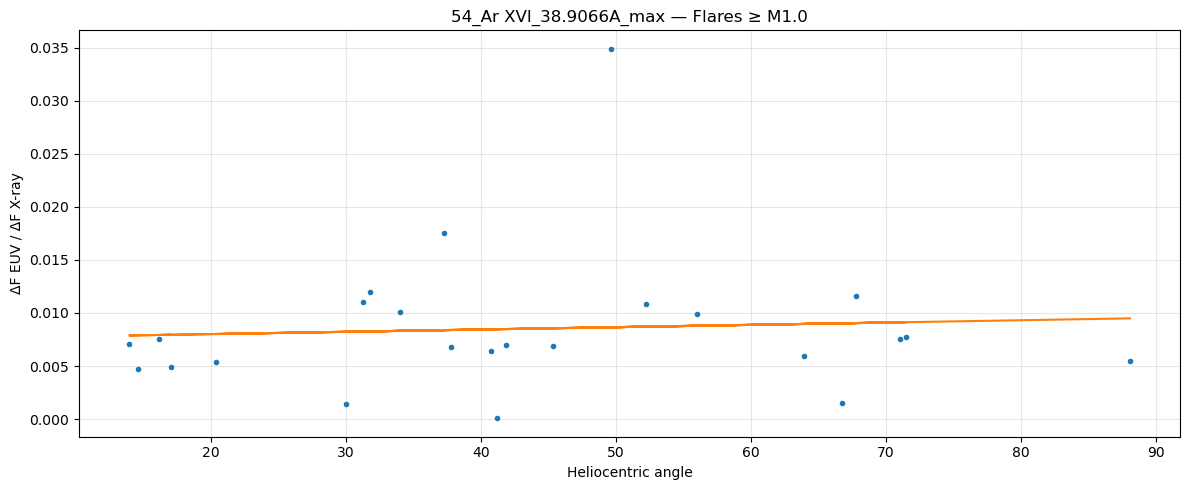

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = 6e-06
r-value = 0.005427
p-value = 0.979922


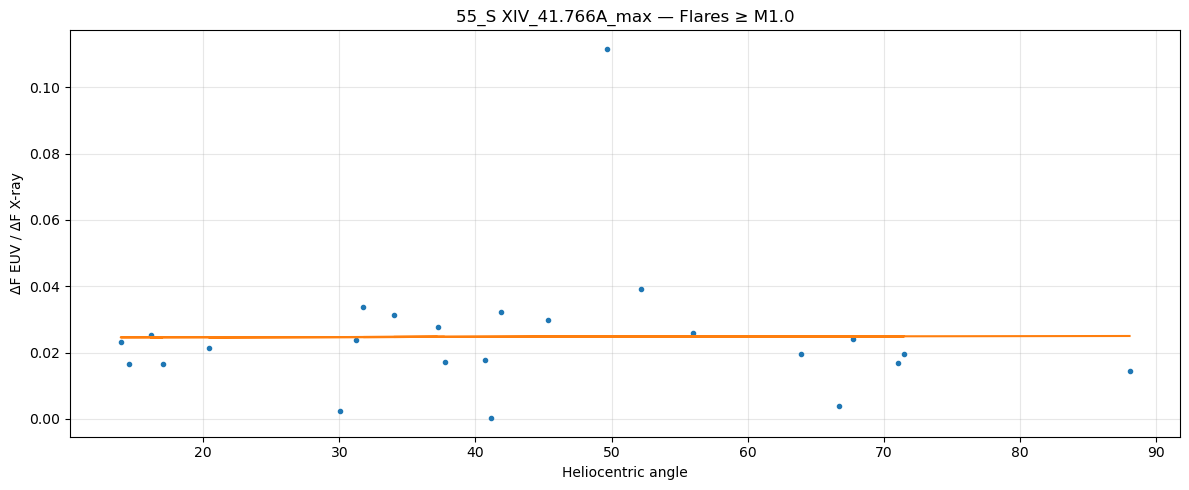

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000159
r-value = -0.417854
p-value = 0.042172


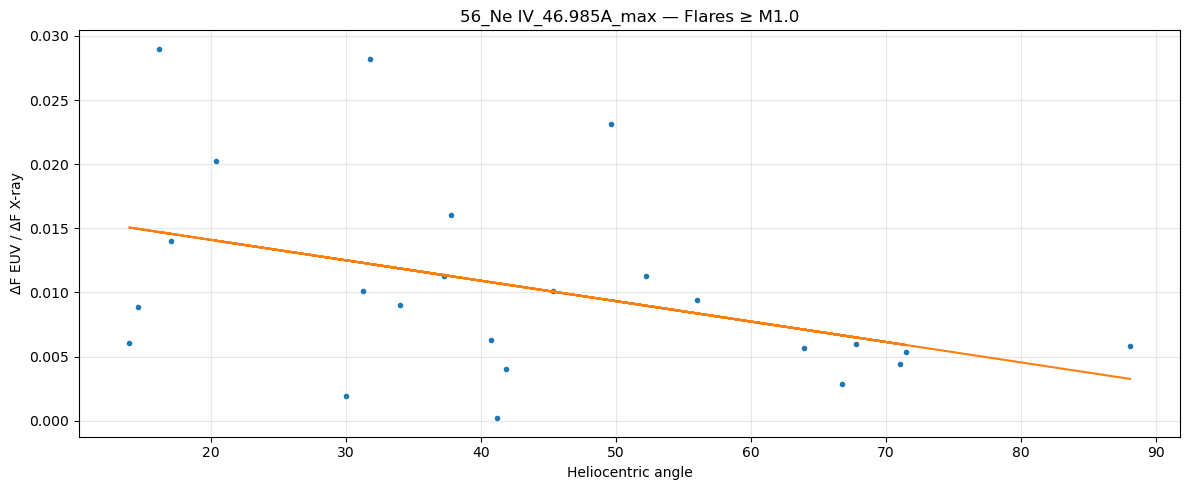

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000562
r-value = -0.475684
p-value = 0.018802


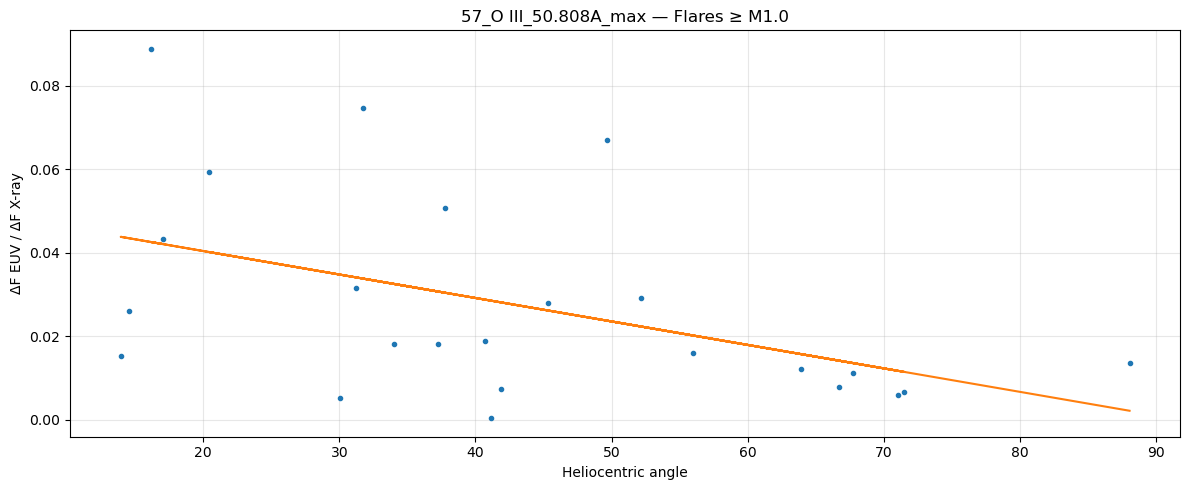

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000127
r-value = -0.357623
p-value = 0.086211


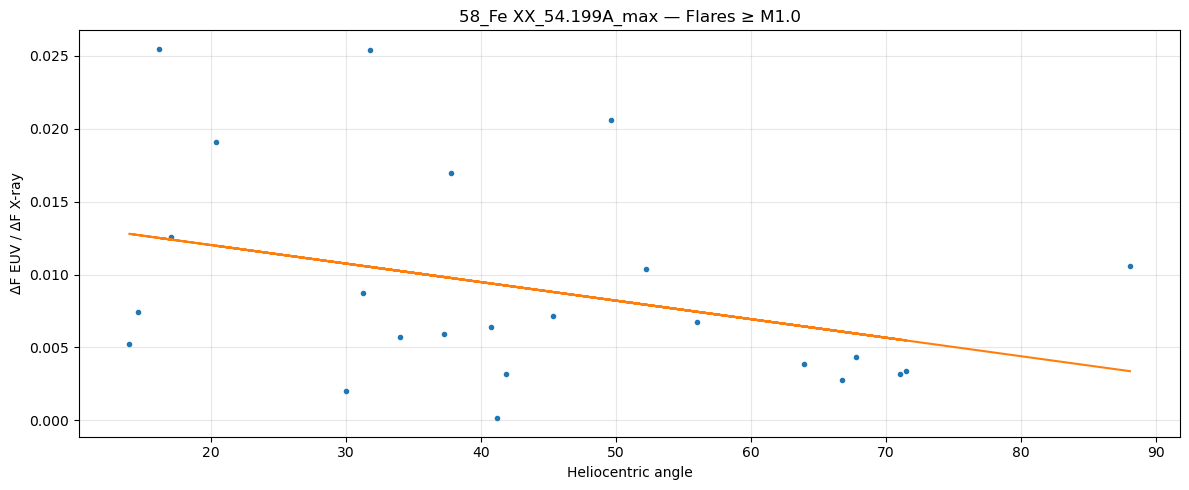

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000159
r-value = -0.429342
p-value = 0.036287


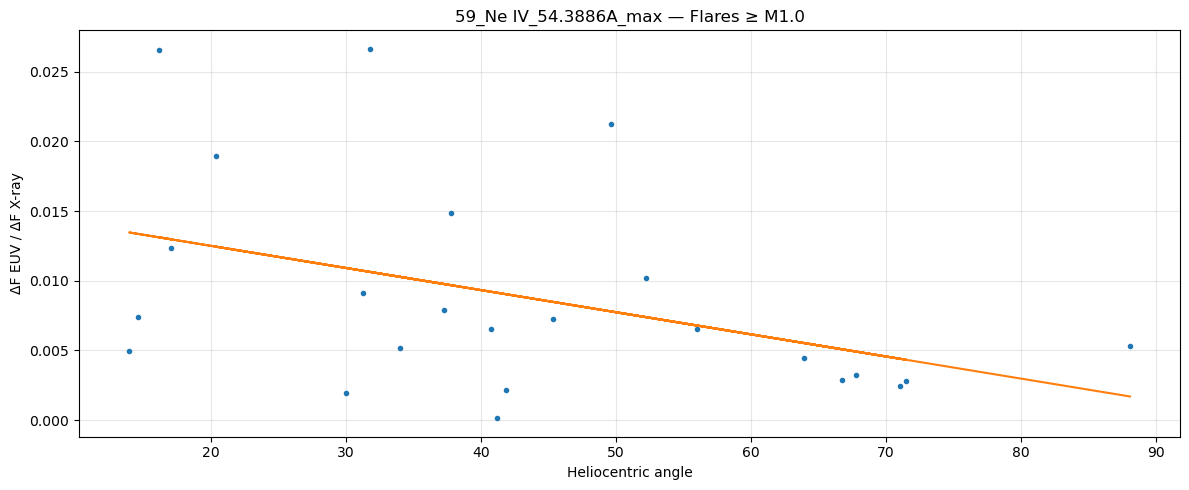

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -2.1e-05
r-value = -0.070603
p-value = 0.74304


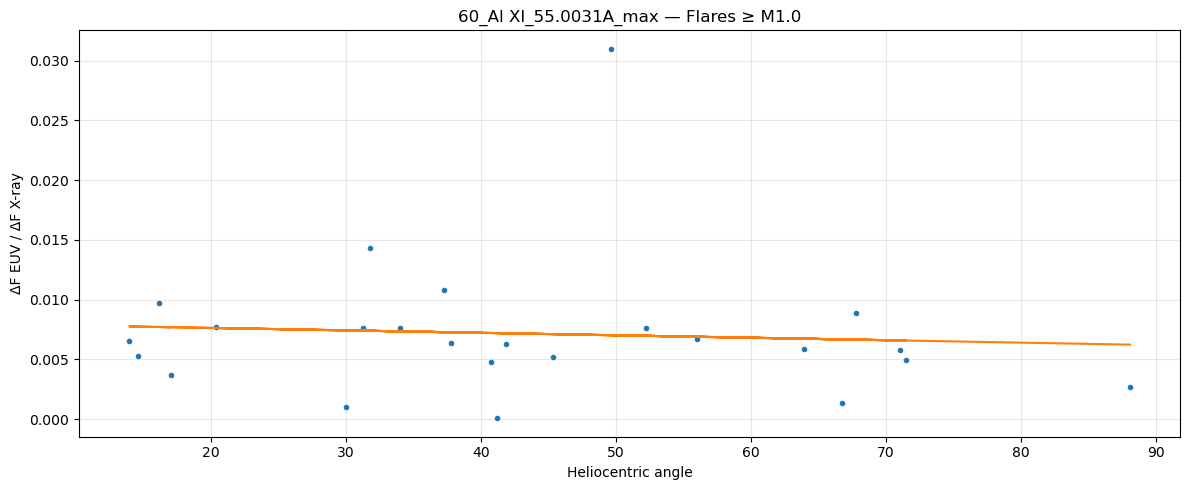

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000168
r-value = -0.445672
p-value = 0.029062


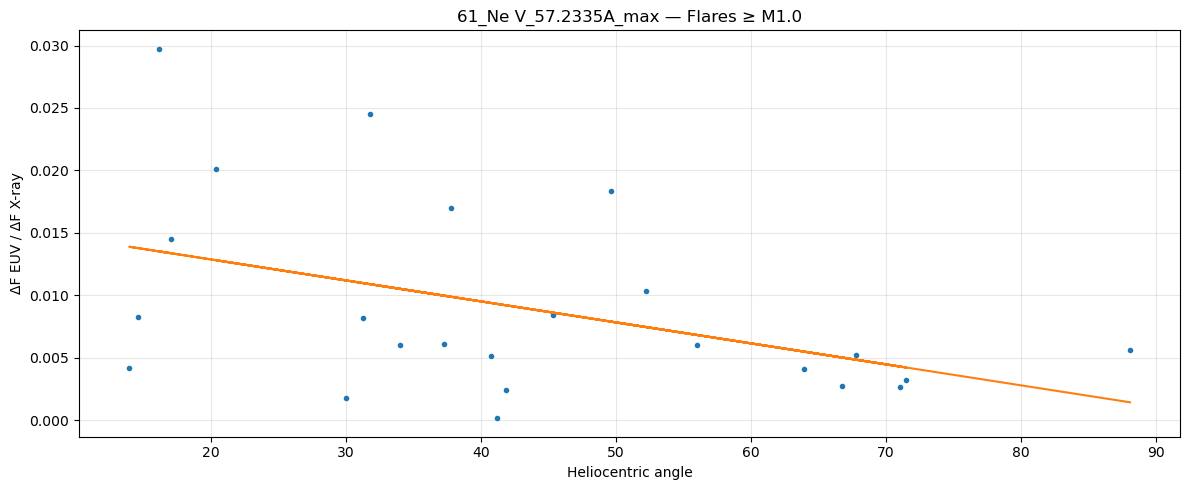

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -3.6e-05
r-value = -0.307439
p-value = 0.143905


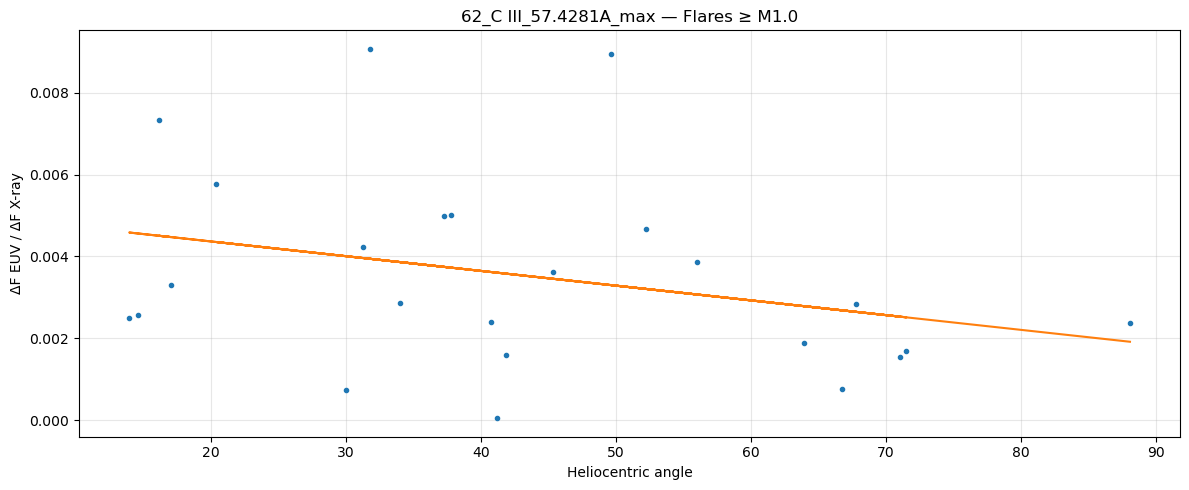

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000963
r-value = -0.431089
p-value = 0.035452


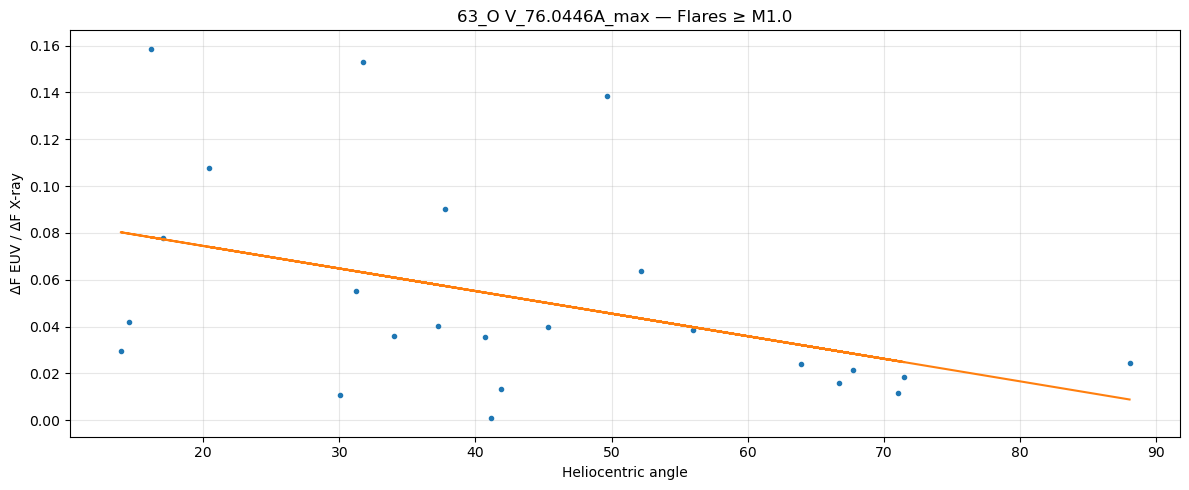

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000925
r-value = -0.416551
p-value = 0.042885


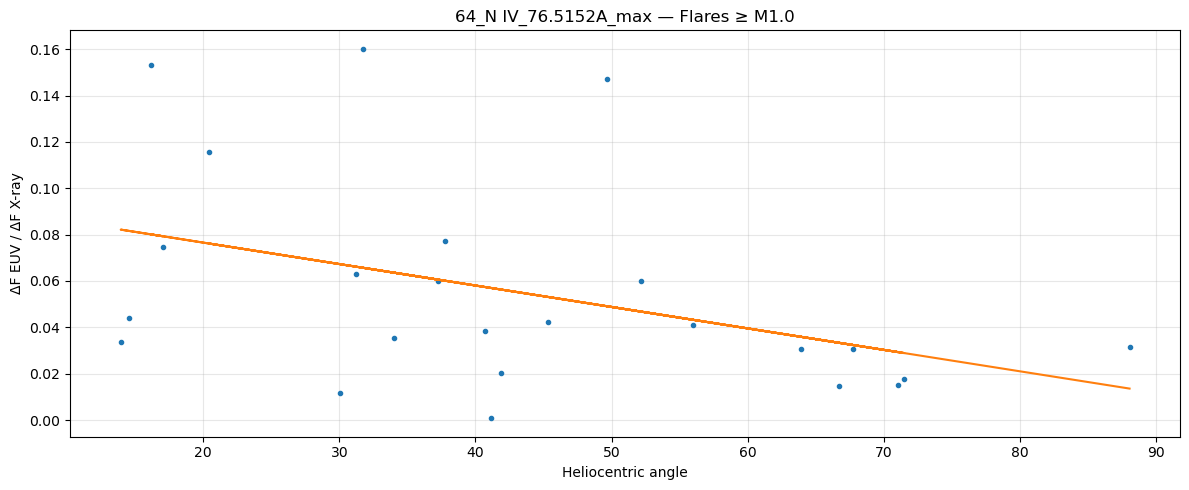

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000917
r-value = -0.410528
p-value = 0.046301


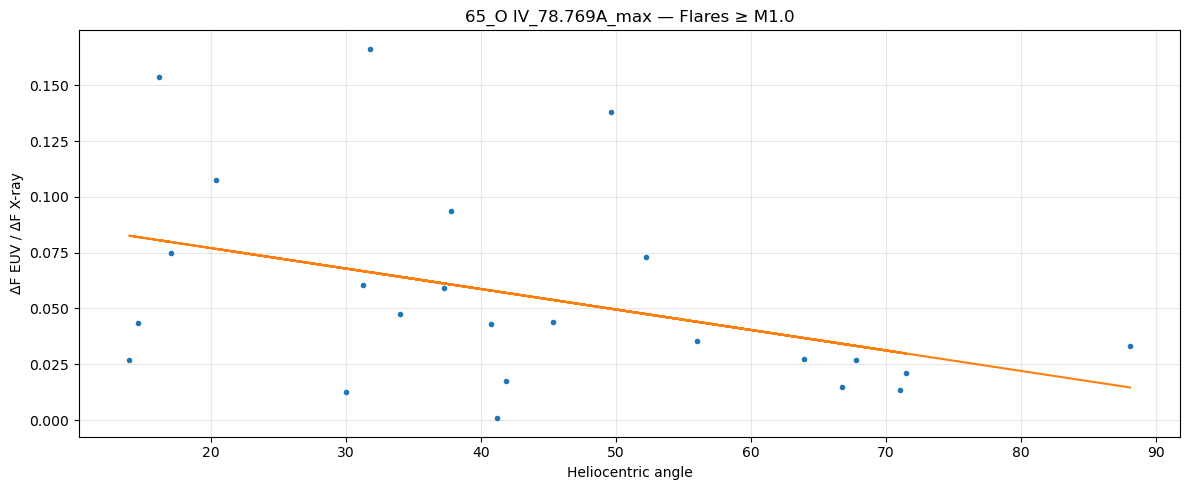

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000159
r-value = -0.141443
p-value = 0.509727


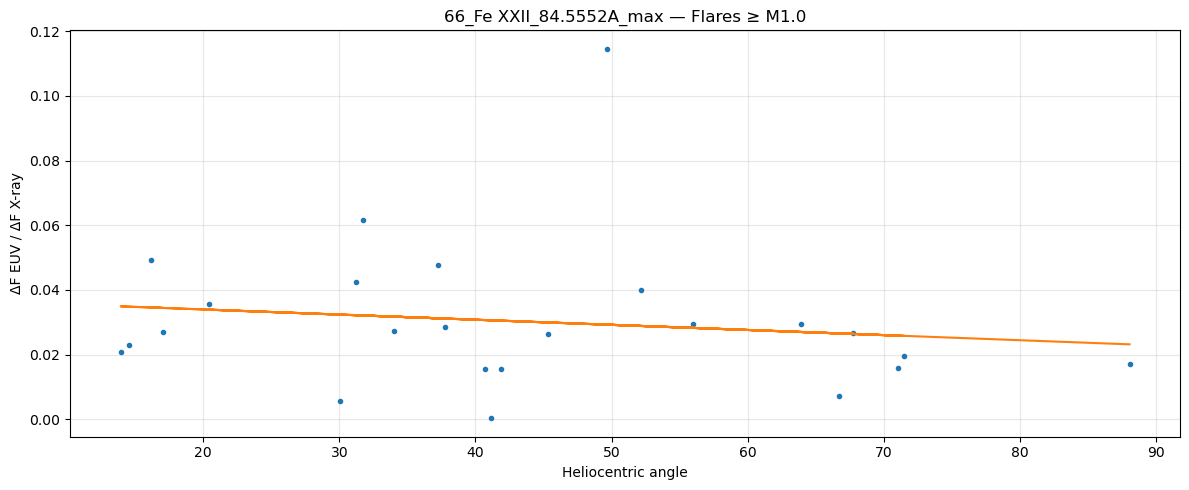

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.00123
r-value = -0.412795
p-value = 0.044991


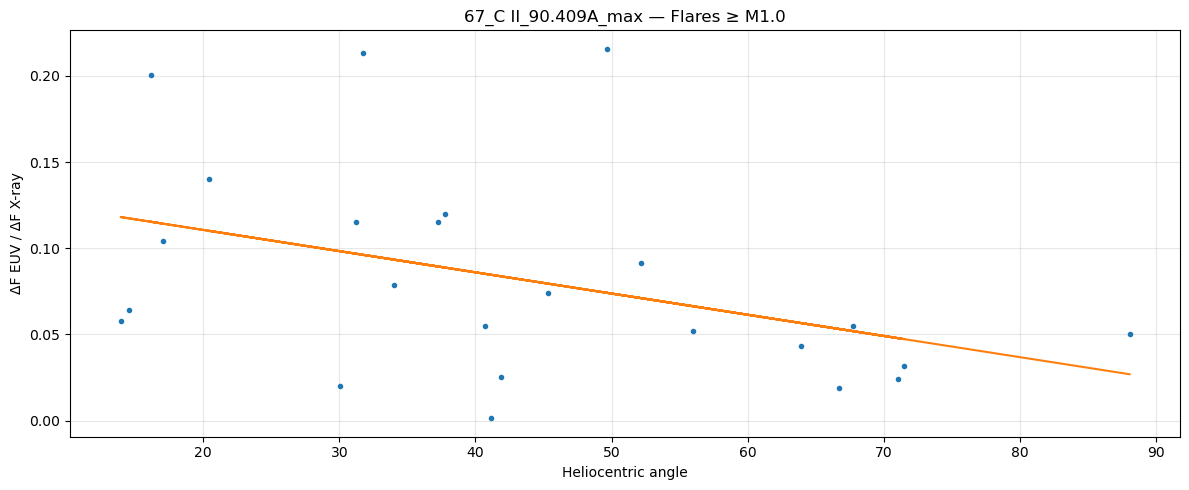

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.001456
r-value = -0.267588
p-value = 0.206183


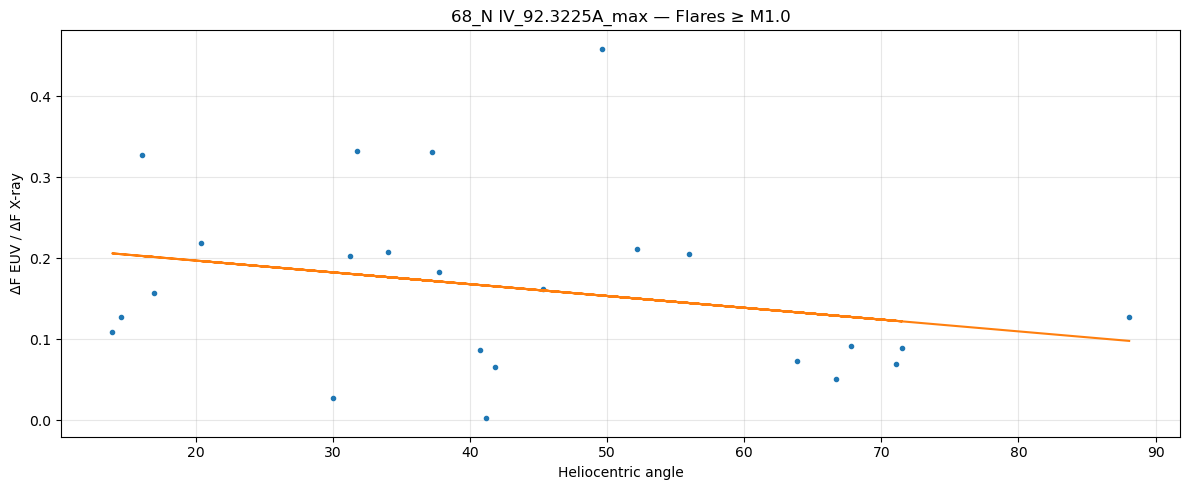

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.000169
r-value = -0.131023
p-value = 0.541694


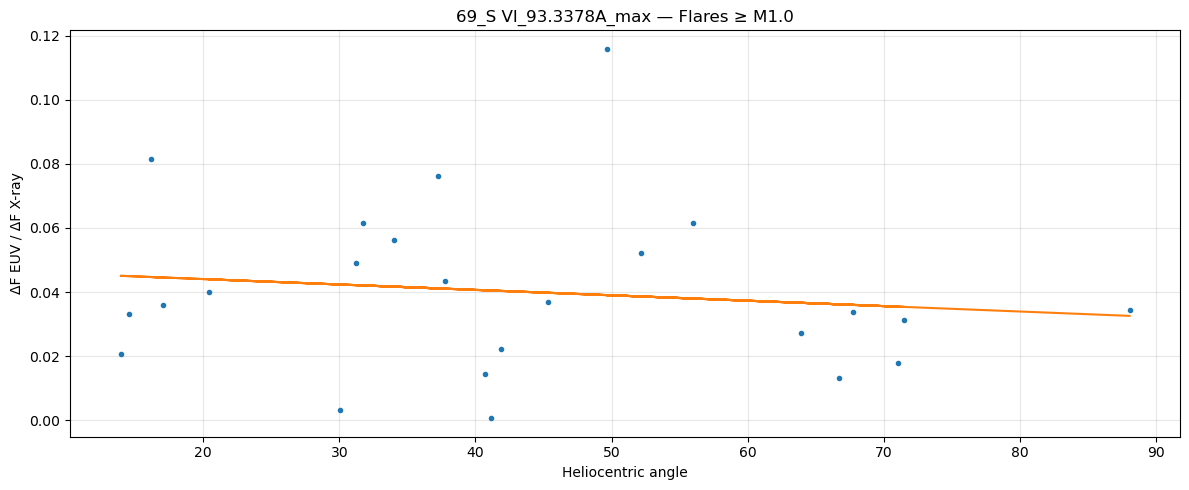

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
slope = -0.006945
r-value = -0.394658
p-value = 0.056326


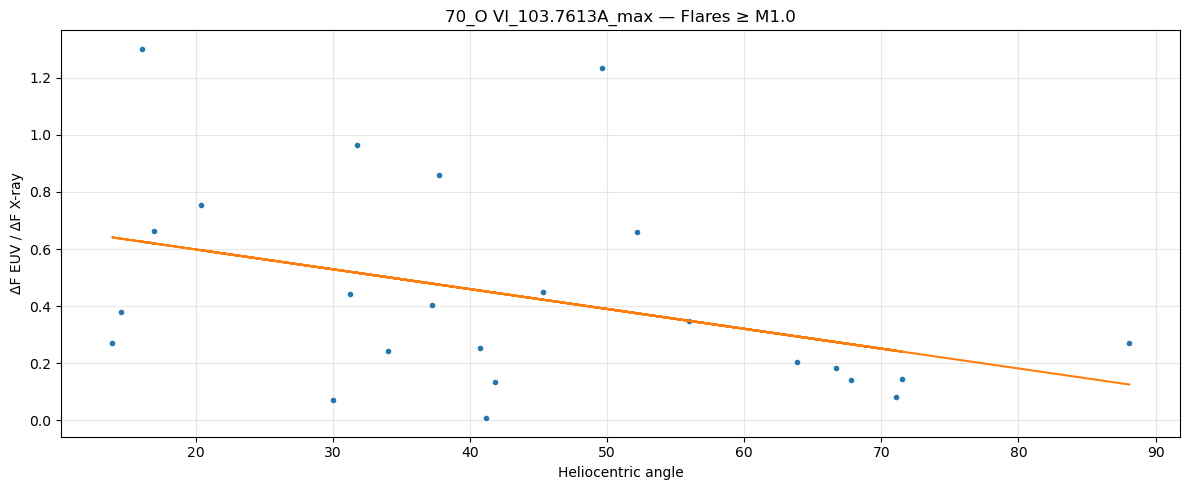

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [41]:

df = pd.read_csv('ai_emission_and_flares_data.csv')

data_lists = {}

for column in df.columns:
    data_lists[column] = df[column].tolist()

titles = list(data_lists.keys())

softxraysflux = data_lists[titles[8]]
Heliocentric_angle = data_lists[titles[5]]
softxback = data_lists[titles[9]]

# Set minimum flare magnitude here
minimum_flare_class = 'M1.0'

def flare_class_to_number(flare_class):
    """
    Convert GOES flare classes to numerical values.
    A1.0 = 1e-8, B1.0 = 1e-7,
    C1.0 = 1e-6, M1.0 = 1e-5,
    X1.0 = 1e-4.
    """
    try:
        flare_class = str(flare_class).strip().upper()
        class_letter = flare_class[0]
        magnitude = float(flare_class[1:])

        class_values = {'A': 1e-8,'B': 1e-7,'C': 1e-6,'M': 1e-5,'X': 1e-4}

        return class_values[class_letter] * magnitude

    except (ValueError, KeyError, IndexError):
        return np.nan


minimum_flux = flare_class_to_number(minimum_flare_class)

# Convert all flare classes to numerical values
flare_magnitudes = [flare_class_to_number(value) for value in data_lists[titles[4]]]

for i in range(10, 81):

    angle = []
    ratio = []
    emission_type_flux=data_lists[titles[i]]
    background=data_lists[titles[i+71]]

    for x in range(len(emission_type_flux)):

        if float(Heliocentric_angle[x])==0.0:
            continue

        # Filter by minimum flare magnitude
        if (np.isfinite(flare_magnitudes[x]) and flare_magnitudes[x] >= minimum_flux):
            if (str(emission_type_flux[x]) == 'nan' or str(softxraysflux[x]) == 'nan' or str(softxback[x]) == 'nan' or str(background[x]) == 'nan'):
                continue

            try:
                euv_change = (float(emission_type_flux[x]) - float(background[x]))
                xray_change = (float(softxraysflux[x]) - float(softxback[x]))

                if xray_change == 0:
                    continue

                ratio.append(euv_change / xray_change)
                angle.append(float(Heliocentric_angle[x]))

            except (ValueError, TypeError):
                continue

    plt.figure(figsize=(12, 5))
    plt.plot(angle, ratio, ".")
    plt.xlabel("Heliocentric angle")
    plt.ylabel("ΔF EUV / ΔF X-ray")
    plt.title(f"{titles[i]} — Flares ≥ {minimum_flare_class}")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    if len(angle) >= 2:
        slope, intercept, rvalue, pvalue, stderr = stats.linregress(angle, ratio)

        plt.plot(angle,slope * np.array(angle) + intercept)

        print('slope =', round(slope, 6))
        print('r-value =', round(rvalue, 6))
        print('p-value =', round(pvalue, 6))
    else:
        print("Not enough data points for regression.")


    
    
    plt.show()

    print('--' * 100)

In [9]:
print('done')

done


In [37]:
print( data_lists[titles[11]][20])

if str(data_lists[titles[11]][20]) == 'nan':
    print('hi')
else:
    print('bye')

nan
hi
